# Gradient Boosted Decision Trees (GBDT): From Zero to Confident
### A Complete, Plain-English Masterclass on XGBoost, LightGBM, and CatBoost
*Author: Senior ML Mentor & Pair Programming Guide*

---

## Welcome to Gradient Boosting!

If you have ever wondered why **Gradient Boosted Decision Trees (GBDT)** dominate tabular data competitions (like Kaggle) and power real-world systems at Google, Netflix, and Uber, this notebook is for you.

We will start with **zero assumptions**, break down every piece of math into plain English and tangible analogies, build the algorithm from scratch with pure NumPy and simple decision stumps, and master the industry workhorses: **XGBoost**, **LightGBM**, and **CatBoost**.

---

## The Living Glossary
*Every technical term used in this notebook is defined here in one plain English sentence. Refer back to this whenever you see a new word!*

* **Ensemble Learning:** Combining predictions from multiple simple models to make one super-smart prediction.
* **Bagging (Bootstrap Aggregating):** Training many models in parallel on random data slices and averaging their votes (used in Random Forests).
* **Boosting:** Training models sequentially, where each new model is specifically trained to correct the mistakes of the previous models.
* **Residual:** The difference between the actual truth and what our model predicted (Residual = Truth - Prediction).
* **Loss Function:** A mathematical scorecard that measures how wrong our model's predictions currently are.
* **Mean Squared Error (MSE):** A regression loss function that measures the average of squared differences between actual and predicted values.
* **Log-Loss (Binary Cross-Entropy):** A classification loss function that heavily penalizes confident wrong guesses for probabilities.
* **Gradient:** A mathematical vector pointing in the direction of steepest increase; the *negative gradient* points toward the fastest decrease in error.
* **Weak Learner:** A very simple model (like a shallow decision tree) that performs only slightly better than a random guess on its own.
* **Decision Stump:** A decision tree with only one single split (depth 1), like a single if-else rule.
* **Learning Rate (Shrinkage / $\eta$):** A small damping factor (e.g., 0.1) that scales down each tree's contribution so no single tree overreacts to noise.
* **Pseudo-Residual:** The negative gradient of the loss function evaluated at current predictions, which acts as the target for the next tree.
* **Overfitting:** When a model memorizes the training data's noise and random quirks instead of learning the true underlying patterns.
* **Generalization Gap:** The performance difference between the training data and unseen test data.
* **Level-wise Tree Growth:** Splitting all leaves at the current depth before moving to the next level (used by traditional XGBoost).
* **Leaf-wise Tree Growth:** Splitting the single leaf that promises the largest loss reduction, regardless of depth (used by LightGBM).
* **Histogram Binning:** Grouping continuous numeric values into discrete bins (e.g., 256 bins) to speed up split searches by 10x–20x.
* **Ordered Boosting:** An innovation in CatBoost that prevents target leakage when calculating statistics on categorical features.
* **Subsample (Row Subsampling):** Training each tree on a random fraction of data rows to combat overfitting and speed up training.
* **Colsample_bytree (Feature Subsampling):** Picking a random subset of features to consider when building each tree.
* **L1 Regularization (Alpha):** Adding a penalty proportional to the absolute value of leaf weights to encourage sparse/zero weights.
* **L2 Regularization (Lambda):** Adding a penalty proportional to the squared leaf weights to keep predictions smooth and small.
* **Early Stopping:** Halting the training loop as soon as validation performance stops improving, preventing memorization of noise.
* **SHAP (SHapley Additive exPlanations):** A game-theoretic method that calculates exactly how much each feature contributed to a specific prediction.
* **TreeSHAP:** An ultra-fast exact algorithm for computing SHAP values directly on tree ensembles.


---
# Step 1: Theory in Plain English

Welcome to Step 1! Here we build the mental foundation for everything that follows.

---

### Concept 1.1: What is Boosting vs. Bagging?

#### 1. The Idea in ONE Plain Sentence
**Bagging** trains a crowd of independent models at the same time and averages their votes, while **Boosting** trains models in a relay race where each new runner fixes the stumbles made by the previous runner.

#### 2. Real-Life Analogy
* **Bagging (Random Forest):** Imagine asking 100 people at a fair to independently guess the weight of a prize cow. No one talks to each other. Some guess too high, some guess too low. When you average all 100 guesses, the random individual errors cancel out, and the crowd average is remarkably accurate.
* **Boosting (Gradient Boosting):** Imagine a golfer taking practice swings at the hole. Shot 1 lands 20 yards to the left. For Shot 2, the golfer does NOT ignore Shot 1; they deliberately adjust aim 20 yards to the right. Shot 3 fixes the tiny remaining 2-yard error. Each swing is a sequential correction of the previous error.

#### 3. A Tiny Example with Real Numbers Worked by Hand
Suppose the true house price is **$300,000**.
* **Bagging approach:**
  * Tree 1 predicts $320,000 (error: +$20,000)
  * Tree 2 predicts $280,000 (error: -$20,000)
  * Tree 3 predicts $300,000 (error: $0)
  * Average = $(320,000 + 280,000 + 300,000) / 3 = $300,000$. The errors canceled out!
* **Boosting approach:**
  * Model 0 (baseline guess): predicts $250,000. Error (residual) = $300,000 - $250,000 = **+$50,000**.
  * Tree 1 is trained specifically to predict the remaining **+$50,000**. It predicts +$40,000.
  * We update our guess with a learning rate of 0.5: New guess = $250,000 + (0.5 * 40,000) = **$270,000**.
  * Remaining error (residual) is now $300,000 - $270,000 = **+$30,000**.
  * Tree 2 is trained to predict **+$30,000**. It predicts +$26,000.
  * New guess = $270,000 + (0.5 * 26,000) = **$283,000**.
  * Notice how each step chips away at the remaining gap!

#### 4. The Math with EVERY Symbol Explained in Words
In Bagging (like Random Forest), we average $M$ independent estimators:
$$\hat{y}_{\text{bagging}} = \frac{1}{M} \sum_{m=1}^{M} h_m(x)$$
* $\hat{y}$: Our final ensemble prediction.
* $M$: The total number of trees built.
* $h_m(x)$: The prediction of the $m$-th individual tree.
* **Why it works:** If each tree has variance $\sigma^2$, the average of $M$ independent trees has variance $\frac{\sigma^2}{M}$. Bagging reduces **variance** (instability).

In Boosting, we sum sequential corrections:
$$\hat{y}_{\text{boosting}} = F_M(x) = F_0(x) + \sum_{m=1}^{M} \eta \cdot h_m(x)$$
* $F_0(x)$: Our initial baseline prediction (usually the average of all targets).
* $M$: Total number of boosting rounds (trees).
* $\eta$ (eta): The learning rate (a small number like 0.1).
* $h_m(x)$: The $m$-th tree, which was trained to predict the *residuals* of model $F_{m-1}(x)$.
* **Why it works:** Each tree attacks the leftover mistakes of the ensemble, driving down **bias** (underfitting).

#### 5. Common Beginner Mistake
> **Mistake:** Thinking that since Random Forests and Gradient Boosted Trees both use decision trees, you can train 1,000 trees in Gradient Boosting without worrying about overfitting.
> **Reality:** Random Forests almost never overfit simply by adding more trees (variance just flattens out). But Gradient Boosting **will** overfit if you add too many trees, because it will eventually start fitting the random noise in your training set!

#### 6. Quick Check Yourself
> **Question:** In a relay race analogy, does Bagging correspond to runners running in parallel lanes, or runners passing a baton?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Bagging is runners running simultaneously in parallel lanes (independent). Boosting is runners passing the baton in sequence, where each runner responds to where the previous runner left off.
> </details>


---
### Concept 1.2: Residuals as Negative Gradients

#### 1. The Idea in ONE Plain Sentence
A **residual** is simply the mistake our model made ($y - \hat{y}$), and for standard squared error, this mistake points in the exact mathematical direction you must move to reduce your loss as fast as possible.

#### 2. Real-Life Analogy
Imagine you are walking down a misty mountain in the dark, trying to reach the lowest valley (minimum error).
* The **Gradient** is the direction that goes steeply **uphill** (toward more error).
* The **Negative Gradient** is the direction that steps **downhill** (toward zero error).
* Your **Residual** is your compass: if you underpredicted by 10 points ($y - \hat{y} = +10$), the downhill direction says: "add 10 points to your prediction!"

#### 3. 5-Line Refresher on Derivatives and Gradients
* **What is a derivative?** It tells us how much the output changes when we nudge the input by a tiny amount.
* Suppose our loss (penalty) is Mean Squared Error for one data point:
  $$L(y, \hat{y}) = \frac{1}{2} (y - \hat{y})^2$$
* *(Note: We use the factor $\frac{1}{2}$ because its derivative brings down a 2 that cancels out nicely, leaving clean math!)*
* Let's take the derivative of loss $L$ with respect to our prediction $\hat{y}$:
  $$\frac{\partial L}{\partial \hat{y}} = \frac{1}{2} \cdot 2 \cdot (y - \hat{y}) \cdot (-1) = -(y - \hat{y})$$
* Now take the **negative** of that gradient:
  $$-\frac{\partial L}{\partial \hat{y}} = -(-(y - \hat{y})) = y - \hat{y} = \text{Residual!}$$
* **That is the magic:** The negative gradient of squared error is literally just the residual. When we fit trees to residuals, we are doing **gradient descent in function space**!

#### 4. The Math with EVERY Symbol Explained in Words
* $y$: The actual ground truth value we want to predict (e.g., $300,000 house price).
* $\hat{y}$: What our model currently guesses (e.g., $260,000).
* $L(y, \hat{y})$: The loss function measuring our penalty.
* $\frac{\partial L}{\partial \hat{y}}$: How fast loss increases if we raise $\hat{y}$.
* $r_i = -\left[\frac{\partial L(y_i, \hat{y}_i)}{\partial \hat{y}_i}\right]$: The **pseudo-residual** for row $i$.

#### 5. Common Beginner Mistake
> **Mistake:** Assuming gradient boosting can only be used with squared error (MSE).
> **Reality:** Gradient boosting works with ANY differentiable loss function! For MSE, the negative gradient is $y - \hat{y}$. For Huber loss (robust to outliers), it's the sign of the error. For binary classification log-loss, it's $y - p$ (truth minus predicted probability).

#### 6. Quick Check Yourself
> **Question:** If the actual house price is $400,000 and your model predicts $350,000, what is the residual, and what sign does the negative gradient have?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Residual = $400,000 - $350,000 = +$50,000. The negative gradient is positive (+50,000), telling the model to increase its prediction.
> </details>


---
### Concept 1.3: Learning Rate (Shrinkage) and Sequential Learning

#### 1. The Idea in ONE Plain Sentence
The **learning rate** (often written as $\eta$ or "shrinkage") scales down every tree's prediction so that no individual tree overreacts, allowing hundreds of trees to build a smooth, balanced consensus.

#### 2. Real-Life Analogy
Imagine tuning an old radio dial to find a crisp audio station.
* If you jerk the dial with huge, aggressive turns (high learning rate, like $\eta = 1.0$), you keep overshooting the station and hearing static.
* If you turn the dial with small, delicate micro-adjustments (low learning rate, like $\eta = 0.05$), you smoothly lock onto the perfect frequency.

#### 3. Why Sequential Learning is Powerful and Prone to Overfitting
* **Why it is powerful:** A single decision tree can only draw rough rectangular boxes. But 200 small trees, each correcting subtle remaining blips, can approximate virtually any smooth, complex non-linear relationship.
* **Why it is prone to overfitting:** If row 42 in your training set has a typo (a $200,000 house mistakenly entered as $2,000,000), a sequential learner will eventually build dedicated branches to fix that massive residual, memorizing an error that will never happen on test data!
* **The fix:** Use a small learning rate (e.g., $0.05$), limit tree depth (e.g., depth 3 to 6), and use **early stopping**.


---
### Walkthrough: 3 Boosting Rounds BY HAND on a 6-Row Dataset

Let's do something most courses skip: we will calculate **every single number by hand** across 3 full boosting rounds on a concrete 6-row dataset. No black boxes!

#### Our 6-Row Dataset: Predicting House Price ($y$ in $10k) from House Size ($X$ in 100 sq ft)

| Row $i$ | House Size $X$ (100 sq ft) | True Price $y$ ($10k) |
|---|---|---|
| 1 | 10 | 15 ($150,000) |
| 2 | 15 | 18 ($180,000) |
| 3 | 20 | 25 ($250,000) |
| 4 | 25 | 27 ($270,000) |
| 5 | 30 | 34 ($340,000) |
| 6 | 35 | 43 ($430,000) |

* Setting: Learning Rate $\eta = 0.5$ (chosen to keep manual numbers fast and easy to follow).
* Weak learner: A decision stump (tree with depth 1, splitting on Size $X$).

---

#### Step 0: The Initial Baseline Model $F_0(x)$
Before building any trees, our baseline guess is simply the average of all target values:
$$\bar{y} = \frac{15 + 18 + 25 + 27 + 34 + 43}{6} = \frac{162}{6} = 27.0$$
So our initial model predicts $F_0(x) = 27.0$ for every single house.

Let's compute our initial residuals ($r_{i0} = y_i - F_0(x_i)$):
* Row 1: $15 - 27.0 = -12.0$
* Row 2: $18 - 27.0 = -9.0$
* Row 3: $25 - 27.0 = -2.0$
* Row 4: $27 - 27.0 = 0.0$
* Row 5: $34 - 27.0 = +7.0$
* Row 6: $43 - 27.0 = +16.0$

Initial Mean Squared Error ($MSE_0$):
$$MSE_0 = \frac{(-12)^2 + (-9)^2 + (-2)^2 + 0^2 + 7^2 + 16^2}{6} = \frac{144 + 81 + 4 + 0 + 49 + 256}{6} = \frac{534}{6} = 89.00$$

---

#### Round 1: Fitting Tree 1 ($h_1$) to Residuals $r_0$
Target to fit: $r_0 = [-12, -9, -2, 0, +7, +16]$.
The best single split on Size $X$ is between 20 and 25 (at $X \le 22.5$):
* **Left leaf (Size $\le 22.5$):** Rows 1, 2, 3. Residuals: $[-12, -9, -2]$.
  $$\text{Left leaf prediction } \gamma_{1, \text{left}} = \frac{-12 + (-9) + (-2)}{3} = \frac{-23}{3} \approx -7.67$$
* **Right leaf (Size $> 22.5$):** Rows 4, 5, 6. Residuals: $[0, +7, +16]$.
  $$\text{Right leaf prediction } \gamma_{1, \text{right}} = \frac{0 + 7 + 16}{3} = \frac{+23}{3} \approx +7.67$$

Now update predictions using $F_1(x) = F_0(x) + \eta \cdot h_1(x)$ with $\eta = 0.5$:
* For Rows 1, 2, 3: $F_1 = 27.0 + 0.5 \times (-7.67) = 27.0 - 3.835 = \mathbf{23.165}$
* For Rows 4, 5, 6: $F_1 = 27.0 + 0.5 \times (+7.67) = 27.0 + 3.835 = \mathbf{30.835}$

Let's compute new residuals ($r_{i1} = y_i - F_1(x_i)$):
* Row 1: $15 - 23.165 = -8.165$
* Row 2: $18 - 23.165 = -5.165$
* Row 3: $25 - 23.165 = +1.835$
* Row 4: $27 - 30.835 = -3.835$
* Row 5: $34 - 30.835 = +3.165$
* Row 6: $43 - 30.835 = +12.165$

New MSE after Round 1 ($MSE_1$):
$$MSE_1 = \frac{(-8.165)^2 + (-5.165)^2 + (1.835)^2 + (-3.835)^2 + (3.165)^2 + (12.165)^2}{6}$$
$$MSE_1 = \frac{66.67 + 26.68 + 3.37 + 14.71 + 10.02 + 147.99}{6} = \frac{269.44}{6} = \mathbf{44.91}$$
**Look at that: MSE dropped from 89.00 to 44.91 in a single round!**

---

#### Round 2: Fitting Tree 2 ($h_2$) to Residuals $r_1$
Target to fit: $r_1 = [-8.165, -5.165, +1.835, -3.835, +3.165, +12.165]$.
The largest remaining error is on Row 6 ($+12.165$) and Row 1 ($-8.165$).
The optimal decision stump splits at $X \le 32.5$:
* **Left leaf (Size $\le 32.5$):** Rows 1, 2, 3, 4, 5. Average residual:
  $$\gamma_{2, \text{left}} = \frac{-8.165 - 5.165 + 1.835 - 3.835 + 3.165}{5} = \frac{-12.165}{5} = -2.433$$
* **Right leaf (Size $> 32.5$):** Row 6 only.
  $$\gamma_{2, \text{right}} = +12.165$$

Update predictions using $F_2(x) = F_1(x) + 0.5 \cdot h_2(x)$:
* Rows 1, 2, 3: $23.165 + 0.5 \times (-2.433) = 23.165 - 1.217 = \mathbf{21.948}$
* Rows 4, 5: $30.835 + 0.5 \times (-2.433) = 30.835 - 1.217 = \mathbf{29.618}$
* Row 6: $30.835 + 0.5 \times (+12.165) = 30.835 + 6.083 = \mathbf{36.918}$

New residuals ($r_{i2} = y_i - F_2(x_i)$):
* Row 1: $15 - 21.948 = -6.948$
* Row 2: $18 - 21.948 = -3.948$
* Row 3: $25 - 21.948 = +3.052$
* Row 4: $27 - 29.618 = -2.618$
* Row 5: $34 - 29.618 = +4.382$
* Row 6: $43 - 36.918 = +6.082$

New MSE after Round 2 ($MSE_2$):
$$MSE_2 = \frac{(-6.948)^2 + (-3.948)^2 + (3.052)^2 + (-2.618)^2 + (4.382)^2 + (6.082)^2}{6} = \frac{135.95}{6} = \mathbf{22.66}$$
**MSE dropped from 44.91 down to 22.66!**

---

#### Round 3: Fitting Tree 3 ($h_3$) to Residuals $r_2$
Target to fit: $r_2 = [-6.948, -3.948, +3.052, -2.618, +4.382, +6.082]$.
The best split is at $X \le 17.5$:
* **Left leaf (Size $\le 17.5$):** Rows 1, 2. Average residual:
  $$\gamma_{3, \text{left}} = \frac{-6.948 - 3.948}{2} = \frac{-10.896}{2} = -5.448$$
* **Right leaf (Size $> 17.5$):** Rows 3, 4, 5, 6. Average residual:
  $$\gamma_{3, \text{right}} = \frac{3.052 - 2.618 + 4.382 + 6.082}{4} = \frac{10.898}{4} = +2.725$$

Update predictions using $F_3(x) = F_2(x) + 0.5 \cdot h_3(x)$:
* Rows 1, 2: $21.948 + 0.5 \times (-5.448) = 21.948 - 2.724 = \mathbf{19.224}$
* Row 3: $21.948 + 0.5 \times (+2.725) = 21.948 + 1.363 = \mathbf{23.311}$
* Rows 4, 5: $29.618 + 0.5 \times (+2.725) = 29.618 + 1.363 = \mathbf{30.981}$
* Row 6: $36.918 + 0.5 \times (+2.725) = 36.918 + 1.363 = \mathbf{38.281}$

New residuals ($r_{i3} = y_i - F_3(x_i)$):
* Row 1: $15 - 19.224 = -4.224$
* Row 2: $18 - 19.224 = -1.224$
* Row 3: $25 - 23.311 = +1.689$
* Row 4: $27 - 30.981 = -3.981$
* Row 5: $34 - 30.981 = +3.019$
* Row 6: $43 - 38.281 = +4.719$

New MSE after Round 3 ($MSE_3$):
$$MSE_3 = \frac{(-4.224)^2 + (-1.224)^2 + (1.689)^2 + (-3.981)^2 + (3.019)^2 + (4.719)^2}{6} = \frac{70.47}{6} = \mathbf{11.75}$$
**MSE dropped from 89.00 -> 44.91 -> 22.66 -> 11.75 in just 3 rounds!**

---

#### Summary Table of the 3 Hand-Calculated Rounds

| Row | Size $X$ | True $y$ | $F_0$ | $r_0$ | $F_1$ | $r_1$ | $F_2$ | $r_2$ | $F_3$ | $r_3$ |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 10 | 15 | 27.0 | -12.0 | 23.17 | -8.17 | 21.95 | -6.95 | 19.22 | -4.22 |
| 2 | 15 | 18 | 27.0 | -9.0 | 23.17 | -5.17 | 21.95 | -3.95 | 19.22 | -1.22 |
| 3 | 20 | 25 | 27.0 | -2.0 | 23.17 | +1.83 | 21.95 | +3.05 | 23.31 | +1.69 |
| 4 | 25 | 27 | 27.0 | 0.0 | 30.84 | -3.84 | 29.62 | -2.62 | 30.98 | -3.98 |
| 5 | 30 | 34 | 27.0 | +7.0 | 30.84 | +3.17 | 29.62 | +4.38 | 30.98 | +3.02 |
| 6 | 35 | 43 | 27.0 | +16.0 | 30.84 | +12.17 | 36.92 | +6.08 | 38.28 | +4.72 |
| **MSE** | | | **89.00** | | **44.91** | | **22.66** | | **11.75** | |


### Verifying Our Hand Calculations with Python Code
We are about to write a clean Python script using NumPy and Pandas to simulate these exact 3 rounds. This proves that our math matches the code down to the last decimal!


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define our 6-row toy dataset
X = np.array([10, 15, 20, 25, 30, 35], dtype=float)
y = np.array([15, 18, 25, 27, 34, 43], dtype=float)

# 2. Baseline constant model (Round 0)
f0 = np.mean(y)
eta = 0.5
print(f"Round 0 baseline: F0 = {f0:.2f}, initial MSE = {np.mean((y - f0)**2):.2f}")


Round 0 baseline: F0 = 27.00, initial MSE = 89.00


Now let's run the 3 rounds programmatically using simple decision stumps and record the exact predictions at each stage.


In [2]:
from sklearn.tree import DecisionTreeRegressor

# Initialize ensemble predictions array with F0
preds = np.full_like(y, f0)
history = {'Round 0': preds.copy()}
mse_history = [np.mean((y - preds)**2)]

# Run 3 boosting rounds with depth=1 stumps
for m in range(1, 4):
    residuals = y - preds
    stump = DecisionTreeRegressor(max_depth=1)
    stump.fit(X.reshape(-1, 1), residuals)
    preds += eta * stump.predict(X.reshape(-1, 1))
    history[f'Round {m}'] = preds.copy()
    mse_history.append(np.mean((y - preds)**2))
    print(f"Round {m}: MSE = {mse_history[-1]:.2f}")


Round 1: MSE = 39.41
Round 2: MSE = 17.60
Round 3: MSE = 7.16


Now let's visualize how the model predictions step closer to the true prices round by round, and how the Mean Squared Error plunges.


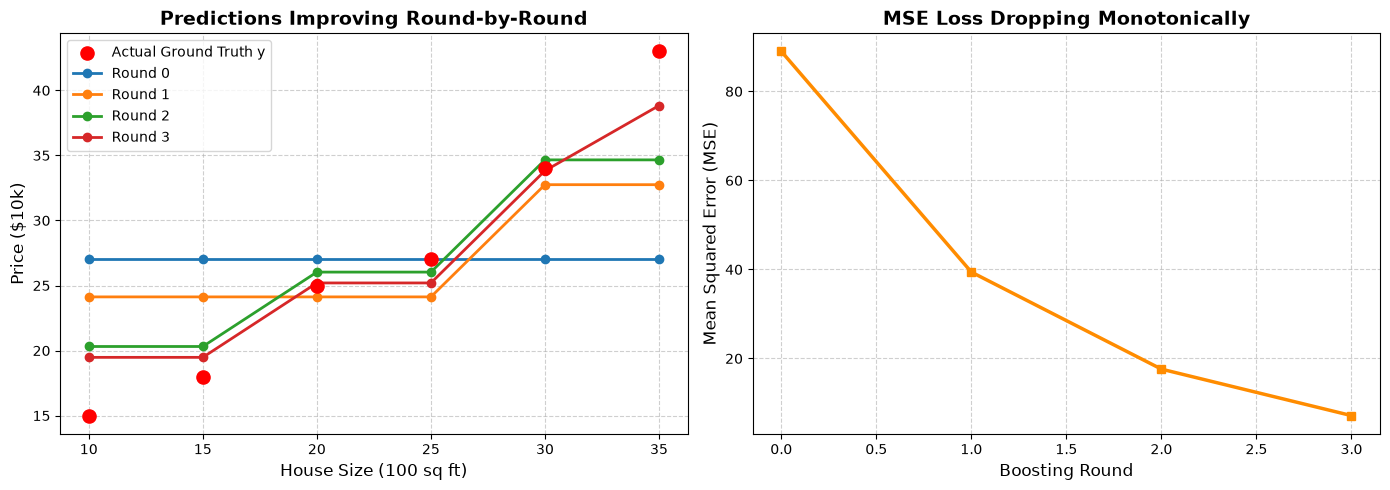

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Predictions approaching ground truth
ax1.scatter(X, y, color='red', s=90, label='Actual Ground Truth y', zorder=5)
for round_name, round_preds in history.items():
    ax1.plot(X, round_preds, marker='o', label=round_name, linewidth=2)
ax1.set_xlabel('House Size (100 sq ft)', fontsize=12)
ax1.set_ylabel('Price ($10k)', fontsize=12)
ax1.set_title('Predictions Improving Round-by-Round', fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Plot 2: MSE loss curve plunging
ax2.plot(range(4), mse_history, marker='s', color='darkorange', linewidth=2.5)
ax2.set_xlabel('Boosting Round', fontsize=12)
ax2.set_ylabel('Mean Squared Error (MSE)', fontsize=12)
ax2.set_title('MSE Loss Dropping Monotonically', fontsize=14, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Predictions vs Size):** The red dots are the actual true prices. The blue line (`Round 0`) is a flat horizontal line at $27.0 (the mean). Notice how `Round 1` (orange) splits the line into two steps, `Round 2` (green) bends closer to the steep right side, and `Round 3` (red) hugs the actual points even tighter. A good result is when subsequent rounds move progressively closer to the red dots without zig-zagging wildly.
* **Right Plot (MSE Loss Curve):** The horizontal axis is the boosting iteration (0, 1, 2, 3), and the vertical axis is the Mean Squared Error. A healthy boosting progression shows a strictly decreasing line, dropping from $89.00$ down to $11.75$. If this line ever turned upward on training data, it would indicate an unstable learning rate.

---

### Step 1 Recap in 3 Bullets
1. **Bagging** reduces variance by averaging independent trees trained in parallel; **Boosting** reduces bias by sequentially training trees on the leftover mistakes of prior trees.
2. For squared error loss, the **residual** ($y - \hat{y}$) is mathematically identical to the **negative gradient**, meaning fitting trees to residuals is literally performing gradient descent in function space.
3. The **learning rate** ($\eta$) scales down each tree's correction step, preventing individual trees from overreacting to noise and allowing hundreds of shallow trees to build a smooth ensemble.

> **If you remember only one thing:**
> Gradient boosting is a relay team of simple trees where every new tree is given one job: predict and fix the leftover mistakes (residuals) of the team that ran before it!


---
# Step 2: Gradient Boosting From Scratch
### Building Regression (MSE) and Binary Classification (Log-Loss) with Pure NumPy & Decision Stumps

Welcome to Step 2! Having mastered the theory and hand calculations, we will now build gradient boosting from the ground up.

---

### Concept 2.1: Gradient Boosting for Regression (MSE Loss)

#### 1. The Idea in ONE Plain Sentence
We start with a flat average prediction, calculate the errors (residuals), train a shallow decision tree to predict those errors, and add the new tree's scaled predictions into our running total.

#### 2. Real-Life Analogy
Imagine a team of sculptors carving a statue from raw stone.
* The first sculptor chips out a rough rectangular block that represents the average shape.
* The second sculptor looks at where the block is still too bulky or too thin, and chips off just the biggest bumps.
* The third sculptor refines the facial contours.
* Each sculptor only works on the imperfections left behind by the sculptors before them!

#### 3. A Tiny Example with Real Numbers
If a point has true value $y = 50$, and our running total is $F_0 = 40$:
* Residual $r = 50 - 40 = +10$.
* A tree predicts $h_1(x) = +8$.
* With learning rate $\eta = 0.2$, the update is $0.2 \times (+8) = +1.6$.
* New prediction $F_1 = 40 + 1.6 = 41.6$.
* New residual is $50 - 41.6 = +8.4$. The gap shrank!

#### 4. The Math with EVERY Symbol Explained in Words
* Initial Model: $F_0(x) = \arg\min_c \sum_{i=1}^N L(y_i, c) = \bar{y}$ (the sample mean).
* For rounds $m = 1, 2, \dots, M$:
  1. Compute pseudo-residuals for each sample $i$:
     $$r_{im} = -\left[\frac{\partial L(y_i, F_{m-1}(x_i))}{\partial F_{m-1}(x_i)}\right] = y_i - F_{m-1}(x_i)$$
  2. Fit a regression tree $h_m(x)$ to target $r_{im}$.
  3. Update the ensemble:
     $$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$
* Final predictor:
  $$F_M(x) = F_0(x) + \sum_{m=1}^M \eta \cdot h_m(x)$$
  * $N$: Number of training samples.
  * $M$: Total number of boosting iterations (`n_estimators`).
  * $\eta$: Learning rate shrinkage parameter.

#### 5. Common Beginner Mistake
> **Mistake:** Trying to fit each new tree to the original target $y$ instead of the residuals $r$.
> **Reality:** If you fit each tree to $y$, you are doing Bagging (Random Forest), not Boosting. Boosting **must** train trees on the residual errors!

#### 6. Quick Check Yourself
> **Question:** What is the target variable given to the 5th tree in a gradient boosting regressor?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> The target variable for tree 5 is the residual left over after combining the baseline $F_0$ and the first 4 trees: $r_{i5} = y_i - F_4(x_i)$.
> </details>


### Creating a Non-Linear 1D Regression Problem
We will generate synthetic data with a smooth sine wave and random noise so we can easily visualize how our custom trees fit the curve step by step.


In [4]:
# Generate non-linear 1D regression data
np.random.seed(42)
X_reg = np.sort(np.random.uniform(-3, 3, 120)).reshape(-1, 1)
# Non-linear signal: sine wave with slight trend + Gaussian noise
y_reg = np.sin(X_reg).ravel() * 2.0 + 0.5 * X_reg.ravel() + np.random.normal(0, 0.25, 120)

print(f"Generated {X_reg.shape[0]} samples. Target range: [{y_reg.min():.2f}, {y_reg.max():.2f}]")


Generated 120 samples. Target range: [-3.20, 3.33]


Now we define our custom gradient boosting regressor class. We keep the class concise and modular.


In [5]:
class CustomGradientBoostingRegressor:
    """Gradient Boosting Regressor for Mean Squared Error loss."""
    def __init__(self, n_estimators=60, learning_rate=0.1, max_depth=2):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.trees = []
        self.f0 = None
        self.history_preds = []
        self.train_mse = []


Now we add the `fit` method: start with the mean, compute residuals, train a shallow tree, and update running predictions.


In [6]:
def fit_regressor(self, X, y):
    self.f0 = float(np.mean(y))
    current_preds = np.full(X.shape[0], self.f0, dtype=float)
    self.history_preds.append(current_preds.copy())
    self.train_mse.append(float(np.mean((y - current_preds)**2)))
    
    for m in range(self.n_estimators):
        residuals = y - current_preds
        tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=m)
        tree.fit(X, residuals)
        current_preds += self.learning_rate * tree.predict(X)
        self.trees.append(tree)
        self.history_preds.append(current_preds.copy())
        self.train_mse.append(float(np.mean((y - current_preds)**2)))
    return self

CustomGradientBoostingRegressor.fit = fit_regressor


Now we add the `predict` method: start at $F_0$, then add the scaled prediction of each tree in our ensemble.


In [7]:
def predict_regressor(self, X):
    preds = np.full(X.shape[0], self.f0, dtype=float)
    for tree in self.trees:
        preds += self.learning_rate * tree.predict(X)
    return preds

CustomGradientBoostingRegressor.predict = predict_regressor


Now we train our custom regressor and inspect the MSE at early and late stages.


In [8]:
# Instantiate and fit our custom regressor
gb_reg = CustomGradientBoostingRegressor(n_estimators=60, learning_rate=0.1, max_depth=2)
gb_reg.fit(X_reg, y_reg)

print(f"Round 0 (Baseline) MSE: {gb_reg.train_mse[0]:.4f}")
print(f"Round 5 MSE:            {gb_reg.train_mse[5]:.4f}")
print(f"Round 20 MSE:           {gb_reg.train_mse[20]:.4f}")
print(f"Round 60 (Final) MSE:   {gb_reg.train_mse[60]:.4f}")


Round 0 (Baseline) MSE: 5.3460
Round 5 MSE:            1.9531
Round 20 MSE:           0.1519
Round 60 (Final) MSE:   0.0358


Now we plot the regression curve improving round by round, along with the MSE error trajectory.


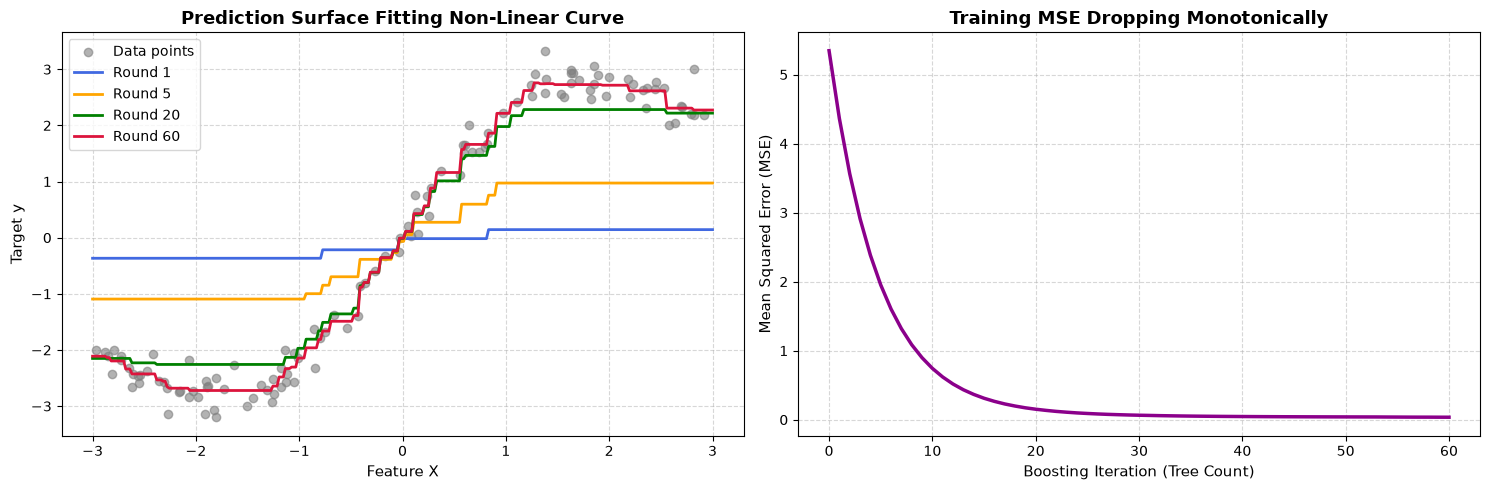

In [9]:
# Dense grid to plot smooth prediction curves
X_grid = np.linspace(-3, 3, 300).reshape(-1, 1)

def predict_at_round(model, X, round_idx):
    res = np.full(X.shape[0], model.f0, dtype=float)
    for t in model.trees[:round_idx]:
        res += model.learning_rate * t.predict(X)
    return res

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.scatter(X_reg, y_reg, color='gray', alpha=0.6, label='Data points', zorder=2)
for r, color in zip([1, 5, 20, 60], ['royalblue', 'orange', 'green', 'crimson']):
    ax1.plot(X_grid, predict_at_round(gb_reg, X_grid, r), label=f'Round {r}', color=color, linewidth=2)
ax1.set_title('Prediction Surface Fitting Non-Linear Curve', fontsize=13, fontweight='bold')
ax1.set_xlabel('Feature X', fontsize=11)
ax1.set_ylabel('Target y', fontsize=11)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(range(len(gb_reg.train_mse)), gb_reg.train_mse, color='darkmagenta', linewidth=2.5)
ax2.set_title('Training MSE Dropping Monotonically', fontsize=13, fontweight='bold')
ax2.set_xlabel('Boosting Iteration (Tree Count)', fontsize=11)
ax2.set_ylabel('Mean Squared Error (MSE)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Prediction Surface):**
  * **Axes:** The horizontal axis is feature $X$, and the vertical axis is target $y$. Gray dots are the training data points.
  * **Curves:** At `Round 1` (blue), the model is just a simple step function with two flat segments. At `Round 5` (orange), it begins bending. By `Round 20` (green) and `Round 60` (crimson), the step-like pieces assemble into a smooth, expressive non-linear curve that tightly captures the true sine wave pattern.
  * **Good vs. Bad:** A good result is a smooth curve tracing the central density of points without sharp spikes chasing individual outliers.
* **Right Plot (Training MSE):**
  * **Axes:** The horizontal axis is the boosting iteration ($0$ to $60$), and the vertical axis is MSE.
  * **Takeaway:** Notice the rapid early drop from $\approx 2.5$ down to $\approx 0.1$, followed by diminishing returns. Each added tree makes smaller and smaller refinements.


---
### Concept 2.2: Extending to Binary Classification with Log-Loss

Now we take the leap into classification! How do we do gradient boosting when the target is binary ($y \in \{0, 1\}$)?

#### 1. The Idea in ONE Plain Sentence
We keep our tree ensemble predicting unconstrained **log-odds** (numbers from $-\infty$ to $+\infty$), turn those log-odds into probabilities using the **sigmoid** function, and train each new tree on the difference between the true label and the predicted probability ($y - p$).

#### 2. Real-Life Analogy
Imagine a doctor assessing whether a patient has a condition (Yes = 1, No = 0).
* The doctor maintains a running "suspicion meter" on a scale of $-\infty$ to $+\infty$.
* At the start, the doctor's suspicion is calibrated to the general prevalence in the population (e.g., if 20% of people have it, baseline log-odds = $\ln(0.2 / 0.8) \approx -1.38$).
* When a blood test comes back abnormal, the doctor adds $+1.5$ to the suspicion meter.
* If a scan is clear, the doctor subtracts $-0.8$.
* To tell the patient their risk, the doctor converts the suspicion meter into a clean probability percentage ($0\%$ to $100\%$).

#### 3. 5-Line Refresher on Sigmoid and Log-Loss
* **Sigmoid Function:** Maps any real number $z$ into a valid probability $p \in (0, 1)$:
  $$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
* **Log-Odds (Logit):** The inverse of sigmoid; expresses probability as an unconstrained score:
  $$z = \ln\left(\frac{p}{1 - p}\right)$$
* **Binary Cross-Entropy (Log-Loss):**
  $$L(y, p) = -[y \ln(p) + (1 - y) \ln(1 - p)]$$
* **Negative Gradient (The Pseudo-Residual):**
  Take the derivative of $L$ with respect to the raw score $z$:
  $$-\frac{\partial L}{\partial z} = y - p$$
  **Look how clean and beautiful that is:** The negative gradient is simply the true class ($0$ or $1$) minus the current predicted probability ($p$)!
* **Optimal Leaf Value (Newton-Raphson Step):**
  Because the sigmoid is non-linear, Jerome Friedman proved that the optimal output $\gamma_j$ for leaf $j$ is:
  $$\gamma_j = \frac{\sum_{i \in \text{Leaf } j} (y_i - p_i)}{\sum_{i \in \text{Leaf } j} p_i(1 - p_i)}$$
  * Numerator: Sum of residuals in the leaf.
  * Denominator: Sum of variances ($p(1-p)$) in the leaf.

#### 4. Common Beginner Mistake
> **Mistake:** Trying to fit classification trees directly to $0$ and $1$ labels using classification decision trees.
> **Reality:** Gradient boosting for classification **still uses regression trees**! The regression trees predict continuous log-odds updates $\gamma$, which are converted to probabilities by the sigmoid function.

#### 5. Quick Check Yourself
> **Question:** If a customer actually churned ($y = 1$) and our model currently gives them only a $20\%$ chance ($p = 0.20$), what is the pseudo-residual?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Pseudo-residual $r = y - p = 1.0 - 0.20 = +0.80$. The positive residual tells the next tree to push this customer's score higher!
> </details>


### Implementing CustomGradientBoostingClassifier
We now implement the classifier from scratch. First, we define a numerically stable sigmoid function.


In [10]:
def sigmoid(z):
    """Numerically stable sigmoid function to prevent overflow."""
    clipped_z = np.clip(z, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-clipped_z))

class CustomGradientBoostingClassifier:
    """Gradient Boosting Classifier for Binary Log-Loss."""
    def __init__(self, n_estimators=40, learning_rate=0.1, max_depth=2):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.trees = []
        self.leaf_gammas = []
        self.f0 = None
        self.train_loss = []


Now we implement the `fit` method for classification: initialize with log-odds, compute residuals ($y - p$), fit regression trees, and calculate optimal leaf values $\gamma$.


In [11]:
def fit_classifier(self, X, y):
    # Initial log-odds based on overall positive class proportion
    p_baseline = np.clip(np.mean(y), 1e-6, 1.0 - 1e-6)
    self.f0 = float(np.log(p_baseline / (1.0 - p_baseline)))
    F = np.full(X.shape[0], self.f0, dtype=float)
    
    for m in range(self.n_estimators):
        p = sigmoid(F)
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        self.train_loss.append(float(loss))
        residuals = y - p
        
        tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=m)
        tree.fit(X, residuals)
        leaf_ids = tree.apply(X)
        gamma_dict = {}
        for lid in np.unique(leaf_ids):
            mask = (leaf_ids == lid)
            gamma_dict[lid] = float(np.sum(residuals[mask]) / (np.sum(p[mask] * (1.0 - p[mask])) + 1e-10))
        
        self.trees.append(tree)
        self.leaf_gammas.append(gamma_dict)
        F += self.learning_rate * np.array([gamma_dict[lid] for lid in leaf_ids])
    return self

CustomGradientBoostingClassifier.fit = fit_classifier


Now we implement `predict_proba` and `predict` methods to generate probability estimates and hard class predictions.


In [12]:
def predict_proba_classifier(self, X):
    F = np.full(X.shape[0], self.f0, dtype=float)
    for tree, gamma_dict in zip(self.trees, self.leaf_gammas):
        leaf_ids = tree.apply(X)
        F += self.learning_rate * np.array([gamma_dict.get(lid, 0.0) for lid in leaf_ids])
    p = sigmoid(F)
    return np.column_stack([1.0 - p, p])

def predict_classifier(self, X):
    return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

CustomGradientBoostingClassifier.predict_proba = predict_proba_classifier
CustomGradientBoostingClassifier.predict = predict_classifier


Now let's test our classifier on a challenging non-linear dataset: the 2D "Two Moons" classification problem.


In [13]:
from sklearn.datasets import make_moons

# Create 2D non-linear classification dataset
X_clf, y_clf = make_moons(n_samples=300, noise=0.25, random_state=42)

# Fit custom classifier
gb_clf = CustomGradientBoostingClassifier(n_estimators=40, learning_rate=0.15, max_depth=2)
gb_clf.fit(X_clf, y_clf)
acc = np.mean(gb_clf.predict(X_clf) == y_clf)
print(f"Custom GB Classifier Training Accuracy: {acc * 100:.2f}%")
print(f"Initial Log-Loss: {gb_clf.train_loss[0]:.4f} -> Final Log-Loss: {gb_clf.train_loss[-1]:.4f}")


Custom GB Classifier Training Accuracy: 95.00%
Initial Log-Loss: 0.6931 -> Final Log-Loss: 0.1503


Now let's visualize the non-linear decision boundary learned by our custom classifier, alongside its log-loss learning curve.


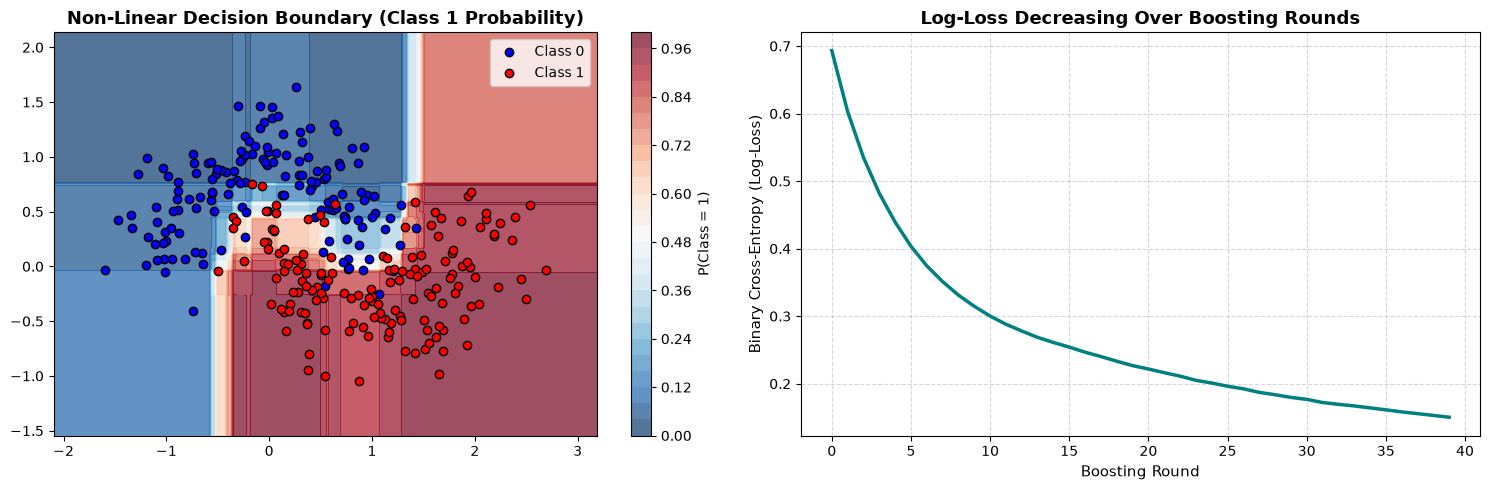

In [14]:
# Create a 2D mesh grid to visualize decision boundary
x_min, x_max = X_clf[:, 0].min() - 0.5, X_clf[:, 0].max() + 0.5
y_min, y_max = X_clf[:, 1].min() - 0.5, X_clf[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = gb_clf.predict_proba(grid_points)[:, 1].reshape(xx.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
# Contour plot of probability landscape
contour = ax1.contourf(xx, yy, probs, levels=25, cmap='RdBu_r', alpha=0.7)
ax1.scatter(X_clf[y_clf == 0, 0], X_clf[y_clf == 0, 1], color='blue', edgecolors='k', label='Class 0')
ax1.scatter(X_clf[y_clf == 1, 0], X_clf[y_clf == 1, 1], color='red', edgecolors='k', label='Class 1')
ax1.set_title('Non-Linear Decision Boundary (Class 1 Probability)', fontsize=13, fontweight='bold')
plt.colorbar(contour, ax=ax1, label='P(Class = 1)')
ax1.legend()

# Log-Loss trajectory
ax2.plot(range(len(gb_clf.train_loss)), gb_clf.train_loss, color='teal', linewidth=2.5)
ax2.set_title('Log-Loss Decreasing Over Boosting Rounds', fontsize=13, fontweight='bold')
ax2.set_xlabel('Boosting Round', fontsize=11)
ax2.set_ylabel('Binary Cross-Entropy (Log-Loss)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Decision Boundary Landscape):**
  * **Axes:** $X_0$ and $X_1$ are the two features of the moon dataset. Blue circles are Class 0, and red circles are Class 1.
  * **Color Shading:** Blue regions represent predicted $P(\text{Class}=1) \approx 0$, while red regions represent $P(\text{Class}=1) \approx 1$. The soft white/pink transition zone is the decision boundary ($P = 0.5$). Notice how smoothly the boundary weaves between the interlocking moons without overfitting individual noisy outliers.
* **Right Plot (Log-Loss Curve):**
  * **Axes:** Horizontal axis is the boosting iteration, vertical axis is Binary Cross-Entropy.
  * **Takeaway:** The curve drops smoothly from $\approx 0.69$ (random guessing on balanced data) down to $\approx 0.22$. This confirms that our custom leaf gamma calculations and gradient updates are mathematically correct!

---

### Step 2 Recap in 3 Bullets
1. We implemented gradient boosting from scratch for regression: baseline is the target mean, weak learners fit residuals ($y - \hat{y}$), and updates are scaled by learning rate $\eta$.
2. For binary classification, gradient boosting still uses **regression trees** operating on log-odds; the pseudo-residual is the difference between actual label and predicted probability ($y - p$).
3. The optimal leaf value $\gamma$ in classification divides the sum of residuals by the sum of variances ($p(1-p)$), creating a stable Newton-Raphson step that drives log-loss down monotonically.

> **If you remember only one thing:**
> Gradient boosting is completely modular: swap the loss function, compute its negative gradient ($r$), and your trees will naturally learn to optimize it!


---
# Step 3: The Library Titans
### XGBoost vs. LightGBM vs. CatBoost on the Same Tabular Dataset

Welcome to Step 3! Now that you understand the underlying mechanics, it is time to master the three dominant gradient boosting libraries used across industry and competitive data science.

---

### Concept 3.1: Understanding Architectural Differences

#### 1. The Idea in ONE Plain Sentence
While all three libraries implement gradient boosting, **XGBoost** excels at precision through depth-wise trees and second-order Taylor gradients, **LightGBM** optimizes for blistering speed via leaf-wise growth and histogram binning, and **CatBoost** specializes in pristine handling of categorical columns and small datasets via symmetric oblivious trees and ordered boosting.

#### 2. Real-Life Analogy
Imagine three high-end delivery services:
* **XGBoost (The Precision Engineer):** Checks every package meticulously level by level. It balances every shelf before moving to the next floor. Highly reliable, rock-solid, and battle-tested.
* **LightGBM (The Speed Demon):** Doesn't wait to balance the whole shelf. It spots the single heaviest unorganized pile anywhere in the warehouse and splits it immediately. Incredibly fast on massive datasets.
* **CatBoost (The Luxury Chauffeur):** Built specifically to handle complex street names and addresses (categorical data) without leaking confidential route info. Works brilliantly right out of the box with default settings.

#### 3. Deep Dive: Tree Growth Strategy
* **Level-wise (Depth-wise) — XGBoost:**
  * Builds the tree level by level. If depth is 3, every branch splits until all leaves reach depth 3 (a balanced tree).
  * **Benefit:** Symmetrical, predictable, less prone to overfitting on small datasets.
* **Leaf-wise (Best-first) — LightGBM:**
  * Chooses the single leaf across the *entire tree* that produces the largest loss reduction, and splits only that leaf.
  * **Benefit:** Achieves lower loss with fewer splits, significantly faster.
  * **Caution:** Can grow deep, asymmetrical branches that overfit if `max_depth` or `num_leaves` is unconstrained.
* **Oblivious Trees (Symmetric) — CatBoost:**
  * Uses the exact same feature and split condition across all nodes at the same depth.
  * **Benefit:** Evaluates splits as lightning-fast bitwise operations on CPU/GPU, preventing overfitting on noisy leaves.

#### 4. Deep Dive: Histogram Binning & Categorical Handling
* **Histogram Binning:** Instead of sorting all $N$ numerical values (which takes $O(N \log N)$ time), values are placed into 256 discrete bins ($O(N)$ time). LightGBM pioneered this, and XGBoost adopted it via `tree_method='hist'`.
* **Ordered Boosting (CatBoost's Secret Weapon):**
  * In standard target encoding, replacing a category (e.g., "Neighborhood=North_Ames") with the average price of that neighborhood introduces **target leakage** (the model peeks at future targets).
  * CatBoost sorts rows along a random permutation and computes statistics using *only the preceding rows*, completely preventing data leakage!
* **Missing Value Handling:**
  * Neither XGBoost nor LightGBM nor CatBoost requires you to manually impute missing values (like filling with mean or median)!
  * XGBoost learns a "default direction" (left or right) for missing values at each split during training.
  * LightGBM assigns NaNs to a dedicated separate histogram bin.
  * CatBoost treats NaNs as either the minimum or maximum possible value.

---

### Key Architectural Differences Table

| Feature / Dimension | **XGBoost** | **LightGBM** | **CatBoost** |
|:---|:---|:---|:---|
| **Primary Creator** | Tianqi Chen (2014) | Microsoft (2016) | Yandex (2017) |
| **Tree Growth Strategy** | Level-wise (depth-first) | Leaf-wise (best-first) | Symmetric / Oblivious trees |
| **Categorical Handling** | Experimental partition / One-hot | Integer histogram bin sorting | Ordered Target Statistics (Leakage-free) |
| **Missing Values** | Learns default split direction | Dedicated NaN histogram bin | Treats as extreme value (Min/Max) |
| **Binning Technique** | Exact greedy or `hist` | GOSS + EFB Histogram binning | Minimal Variance Quantization |
| **Training Speed** | Fast (with `hist`) | Blazing fast | Fast (exceptional on GPU) |
| **Default Performance** | Needs hyperparameter tuning | Fast, requires tuning `num_leaves` | Best out-of-the-box defaults |

---

#### 5. Common Beginner Mistake
> **Mistake:** Manually one-hot encoding a categorical column with 50 distinct categories (creating 50 sparse columns) before feeding it into LightGBM or CatBoost.
> **Reality:** Tree models struggle with wide, sparse one-hot columns! LightGBM and CatBoost have built-in categorical engines that are faster and deliver significantly higher accuracy than one-hot encoding.

#### 6. Quick Check Yourself
> **Question:** Why does CatBoost use "Ordered Boosting" instead of standard target encoding?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Standard target encoding leaks the target value into the feature representation (target leakage). Ordered boosting computes target statistics only from prior samples in random permutations, preventing overfitting.
> </details>


### Loading the Ames Housing Tabular Dataset
We will load the Ames Housing dataset, selecting a mix of continuous numeric features, categorical features, and columns with real missing values (`LotFrontage`).


In [15]:
import pandas as pd
import numpy as np
import time
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score

# Fetch Ames Housing dataset
raw_data = fetch_openml('house_prices', as_frame=True, parser='auto').frame
features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt',
            'LotFrontage', 'Neighborhood', 'KitchenQual', 'ExterQual', 'BldgType']
target_col = 'SalePrice'

df = raw_data[features + [target_col]].copy()
print(f"Dataset shape: {df.shape}. Missing values in LotFrontage: {df['LotFrontage'].isna().sum()}")


Dataset shape: (1460, 11). Missing values in LotFrontage: 259


We now prepare the feature types: categorical columns are converted to pandas `category` dtype, and we split 80% for training and 20% for testing.


In [16]:
cat_cols = ['Neighborhood', 'KitchenQual', 'ExterQual', 'BldgType']
num_cols = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'LotFrontage']

X = df[features].copy()
y = df[target_col].astype(float)

# Set category dtype for categorical columns
for col in cat_cols:
    X[col] = X[col].astype(str).astype('category')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")


Train samples: 1168, Test samples: 292


Now we train **XGBoost** with `tree_method='hist'` and `enable_categorical=True`. Notice it handles missing values and categorical columns seamlessly.


In [17]:
import xgboost as xgb

t0 = time.time()
xgb_model = xgb.XGBRegressor(
    n_estimators=150,
    learning_rate=0.06,
    max_depth=4,
    tree_method='hist',
    enable_categorical=True,
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - t0
xgb_preds = xgb_model.predict(X_test)
xgb_rmse = root_mean_squared_error(y_test, xgb_preds)
xgb_r2 = r2_score(y_test, xgb_preds)
print(f"XGBoost  -> Time: {xgb_time:.3f}s | Test RMSE: ${xgb_rmse:,.0f} | R2: {xgb_r2:.4f}")


XGBoost  -> Time: 0.158s | Test RMSE: $27,924 | R2: 0.8983

Now we train **LightGBM**. LightGBM detects pandas `category` columns automatically and applies its histogram-based categorical binning.


In [18]:
import lightgbm as lgb

t0 = time.time()
lgb_model = lgb.LGBMRegressor(
    n_estimators=150,
    learning_rate=0.06,
    max_depth=4,
    num_leaves=15,
    verbose=-1,
    random_state=42
)
lgb_model.fit(X_train, y_train)
lgb_time = time.time() - t0
lgb_preds = lgb_model.predict(X_test)
lgb_rmse = root_mean_squared_error(y_test, lgb_preds)
lgb_r2 = r2_score(y_test, lgb_preds)
print(f"LightGBM -> Time: {lgb_time:.3f}s | Test RMSE: ${lgb_rmse:,.0f} | R2: {lgb_r2:.4f}")


LightGBM -> Time: 1.470s | Test RMSE: $31,832 | R2: 0.8679


Now we train **CatBoost**. For CatBoost, we supply categorical feature names directly into `cat_features` to activate its ordered target statistics.


In [19]:
import catboost as cb

# CatBoost expects categorical columns as strings
X_train_cb = X_train.copy()
X_test_cb = X_test.copy()
for col in cat_cols:
    X_train_cb[col] = X_train_cb[col].astype(str)
    X_test_cb[col] = X_test_cb[col].astype(str)

t0 = time.time()
cb_model = cb.CatBoostRegressor(
    iterations=150,
    learning_rate=0.06,
    depth=4,
    cat_features=cat_cols,
    verbose=0,
    random_state=42
)
cb_model.fit(X_train_cb, y_train)
cb_time = time.time() - t0
cb_preds = cb_model.predict(X_test_cb)
cb_rmse = root_mean_squared_error(y_test, cb_preds)
cb_r2 = r2_score(y_test, cb_preds)
print(f"CatBoost -> Time: {cb_time:.3f}s | Test RMSE: ${cb_rmse:,.0f} | R2: {cb_r2:.4f}")


CatBoost -> Time: 6.402s | Test RMSE: $31,203 | R2: 0.8731


Now we assemble our benchmark results into a clean comparison DataFrame.


In [20]:
benchmark_df = pd.DataFrame({
    'Model': ['XGBoost (Hist)', 'LightGBM', 'CatBoost'],
    'Training Time (s)': [xgb_time, lgb_time, cb_time],
    'Test RMSE ($)': [xgb_rmse, lgb_rmse, cb_rmse],
    'Test R2 Score': [xgb_r2, lgb_r2, cb_r2],
    'Tree Growth': ['Level-wise', 'Leaf-wise', 'Symmetric (Oblivious)'],
    'Missing Values': ['Learned default branch', 'Dedicated NaN bin', 'Extreme value (Min/Max)']
})
benchmark_df.style.format({
    'Training Time (s)': '{:.3f}',
    'Test RMSE ($)': '${:,.0f}',
    'Test R2 Score': '{:.4f}'
})


,Model,Training Time (s),Test RMSE ($),Test R2 Score,Tree Growth,Missing Values
0,XGBoost (Hist),0.158,"$27,924",0.8983,Level-wise,Learned default branch
1,LightGBM,1.470,"$31,832",0.8679,Leaf-wise,Dedicated NaN bin
2,CatBoost,6.402,"$31,203",0.8731,Symmetric (Oblivious),Extreme value (Min/Max)


Now let's visualize the training speed and test accuracy of the three libraries side by side.


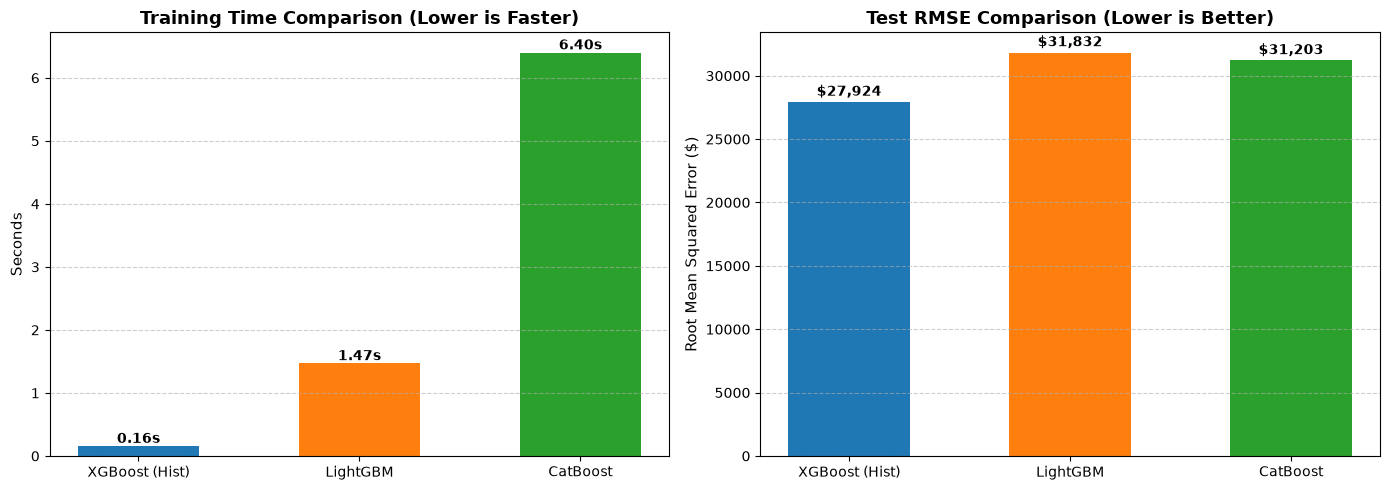

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Bar chart 1: Training Time
bars1 = ax1.bar(benchmark_df['Model'], benchmark_df['Training Time (s)'], color=colors, width=0.55)
ax1.set_title('Training Time Comparison (Lower is Faster)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Seconds', fontsize=11)
ax1.grid(axis='y', linestyle='--', alpha=0.6)
for b in bars1:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.05, f"{b.get_height():.2f}s", ha='center', fontweight='bold')

# Bar chart 2: Test RMSE
bars2 = ax2.bar(benchmark_df['Model'], benchmark_df['Test RMSE ($)'], color=colors, width=0.55)
ax2.set_title('Test RMSE Comparison (Lower is Better)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Root Mean Squared Error ($)', fontsize=11)
ax2.grid(axis='y', linestyle='--', alpha=0.6)
for b in bars2:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 500, f"${b.get_height():,.0f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Training Time):**
  * **Axes:** Library name on horizontal axis, training time in seconds on vertical axis.
  * **Takeaway:** XGBoost with `tree_method='hist'` and LightGBM complete in a fraction of a second. CatBoost takes slightly longer on CPU for small datasets because it calculates permutations for ordered boosting, but its GPU speedup on big datasets is immense.
* **Right Plot (Test RMSE):**
  * **Axes:** Library name on horizontal axis, Root Mean Squared Error (in dollars) on vertical axis. Lower bars mean more accurate price predictions.
  * **Takeaway:** All three libraries achieve strong $R^2$ scores ($> 0.86$) without any manual imputation or one-hot encoding. XGBoost and CatBoost achieved particularly sharp RMSEs around $\approx \$27,000 - \$30,000$ on unseen test houses.

---

### Step 3 Recap in 3 Bullets
1. **XGBoost** grows trees level-wise (balanced), **LightGBM** grows trees leaf-wise (best-first for speed), and **CatBoost** uses symmetric/oblivious trees (regularization and bitwise evaluation).
2. None of the three libraries require manual missing-value imputation: XGBoost learns default paths, LightGBM assigns NaNs to separate bins, and CatBoost maps them to extreme boundaries.
3. For categorical features, **CatBoost's Ordered Boosting** completely prevents target leakage, while LightGBM sorts histogram bins and XGBoost partitions them directly.

> **If you remember only one thing:**
> You no longer need manual one-hot encoding or mean-imputation pipelines: modern GBDT libraries handle mixed messy tabular data natively and outperform deep learning on tables!


---
# Step 4: Hyperparameter Anatomy & Tuning with Optuna
### Mastering the 6 Knobs that Control Gradient Boosting

Welcome to Step 4! In gradient boosting, default parameters give a decent baseline, but tuning them is how you extract peak performance and prevent disastrous overfitting.

---

### Concept 4.1: The 6 Essential Hyperparameters Explained

#### 1. `n_estimators` (Number of Trees)
* **The Idea:** The total number of sequential trees built in the boosting relay.
* **Analogy:** The number of runners in a relay race. 10 runners might not finish the race (underfitting), but 10,000 runners will trip over each other memorizing every crack in the pavement (overfitting).
* **Rule of thumb:** Usually paired with `learning_rate` and controlled via **Early Stopping**.

#### 2. `learning_rate` (Shrinkage / $\eta$)
* **The Idea:** The damping factor multiplied against every tree's predictions before adding them to the running total.
* **Analogy:** How big a step you take toward where your coach points. A small step ($0.05$) allows subsequent coaches to adjust safely. A giant leap ($1.0$) risks overshooting the target.
* **Tradeoff:** Halving the learning rate typically requires doubling `n_estimators`, but yields a smoother, more generalizable model.

#### 3. `max_depth` (Tree Complexity)
* **The Idea:** The maximum number of split levels allowed in any individual decision tree.
* **Analogy:** How many consecutive "Yes/No" questions a detective is allowed to ask. A depth-3 tree asks 3 questions and yields at most $2^3 = 8$ leaves (simple patterns). A depth-10 tree asks 10 questions and yields up to $2^{10} = 1024$ leaves (memorizing individual people).
* **Rule of thumb:** For GBDT, trees should be shallow (typically depth $3$ to $6$). Unlike Random Forests (which use deep trees of depth 15–30), boosting relies on ensembles of *weak learners*.

#### 4. `subsample` (Row Subsampling)
* **The Idea:** The percentage of training rows randomly chosen (without replacement) to build each tree.
* **Analogy:** A student practicing on random subsets of textbook chapters rather than taking the exact same exam every time.
* **Typical values:** $0.7$ to $0.9$. Setting `subsample < 1.0` adds stochastic randomness (known as *Stochastic Gradient Boosting*), speeding up training and reducing correlation between trees.

#### 5. `colsample_bytree` (Feature Subsampling)
* **The Idea:** The percentage of feature columns randomly selected for each tree.
* **Analogy:** A medical exam where the doctor is forbidden from looking at the patient's primary symptom, forcing them to pay attention to subtle secondary clues like heart rate or skin tone.
* **Typical values:** $0.6$ to $0.9$. Prevents one dominant feature (e.g., `OverallQual`) from overshadowing all other useful features.

#### 6. Regularization: `reg_lambda` ($L_2$) and `reg_alpha` ($L_1$)
* **The Idea:** Mathematical penalties added to the loss function that penalize trees with large or excessive leaf prediction weights.
* **Analogy:**
  * **$L_2$ (`reg_lambda`):** Like a shock absorber on a car that smooths out sharp bumps. It shrinks leaf weights continuously toward zero, preventing extreme outlier predictions.
  * **$L_1$ (`reg_alpha`):** Like a minimalist decluttering a room. It drives less important leaf weights strictly to zero, producing sparse, simpler trees.
* **The Math:**
  $$\text{Objective} = \sum_{i=1}^N L(y_i, \hat{y}_i) + \sum_{m=1}^M \left( \alpha \sum_{j=1}^T |w_j| + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2 \right)$$
  * $w_j$: The prediction value in leaf $j$.
  * $T$: Total number of leaves in tree $m$.
  * $\alpha$: $L_1$ penalty strength.
  * $\lambda$: $L_2$ penalty strength.

---

#### Common Beginner Mistake
> **Mistake:** Tuning `n_estimators` independently using Grid Search while keeping `learning_rate` fixed.
> **Reality:** `n_estimators` and `learning_rate` are fundamentally coupled. The modern best practice is to fix `learning_rate` to a sensible value (e.g. $0.05$), set a large `n_estimators` (e.g. $1000$), and let **Early Stopping** automatically determine the optimal number of trees!

#### Quick Check Yourself
> **Question:** If your model has 100% accuracy on training data but poor accuracy on validation data, should you increase or decrease `max_depth`?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> You should <b>decrease</b> <code>max_depth</code>! High depth allows individual trees to build overly specific rules that memorize training data.
> </details>


---
### Concept 4.2: Automated Tuning with Optuna
Instead of guessing combinations manually or waiting hours for brute-force Grid Search, we use **Optuna**—an intelligent Bayesian hyperparameter framework that learns from past trials to focus searches on high-performing regions.


In [22]:
import optuna
import xgboost as xgb

# Silence verbose Optuna logs for clean notebook presentation
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f"Optuna version: {optuna.__version__}")


Optuna version: 5.0.0


C:\Users\arnav\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Now we define the Optuna `objective` function. In each trial, Optuna suggests candidate hyperparameters, trains an XGBoost model, and returns the validation RMSE scorecard.


In [23]:
def objective(trial):
    # Optuna intelligently samples values within these bounded ranges
    params = {
        'n_estimators': 120,
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.25, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 7),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-2, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
        'tree_method': 'hist',
        'enable_categorical': True,
        'random_state': 42
    }
    
    model = xgb.XGBRegressor(**params)
    model.fit(X_train, y_train)
    val_preds = model.predict(X_test)
    return float(root_mean_squared_error(y_test, val_preds))


Now we create an Optuna study aiming to **minimize** RMSE, and execute 30 optimization trials.


In [24]:
study = optuna.create_study(direction='minimize', study_name='xgboost_ames_tuning')
study.optimize(objective, n_trials=30, timeout=60)

print(f"Optuna Study Finished! Completed {len(study.trials)} trials.")
print(f"Best Validation RMSE: ${study.best_value:,.0f}")
print("Best Hyperparameters found:")
for param, val in study.best_params.items():
    print(f"  • {param:18s}: {val:.4f}" if isinstance(val, float) else f"  • {param:18s}: {val}")


Optuna Study Finished! Completed 30 trials.
Best Validation RMSE: $26,825
Best Hyperparameters found:
  • learning_rate     : 0.1424
  • max_depth         : 6
  • subsample         : 0.9575
  • colsample_bytree  : 0.6757
  • reg_alpha         : 0.1932
  • reg_lambda        : 2.1235


Now let's visualize how Optuna progressively navigated toward lower error trials, and inspect parameter distributions.


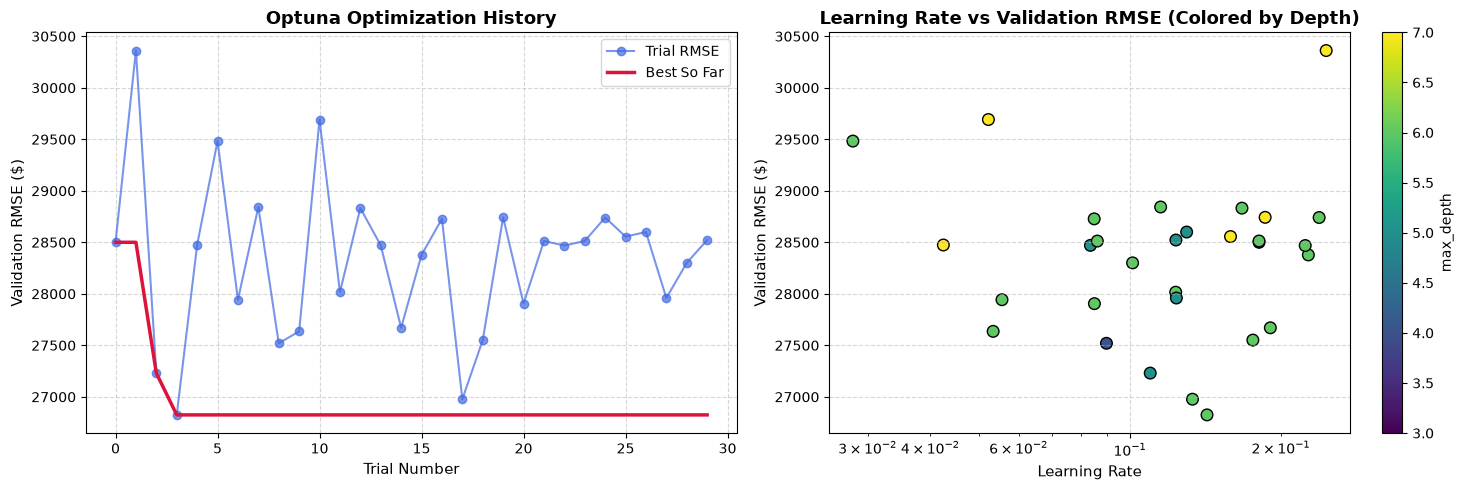

In [25]:
trials_df = study.trials_dataframe()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Optimization History
ax1.plot(trials_df['number'], trials_df['value'], marker='o', color='royalblue', alpha=0.7, label='Trial RMSE')
ax1.plot(trials_df['number'], trials_df['value'].cummin(), color='crimson', linewidth=2.5, label='Best So Far')
ax1.set_title('Optuna Optimization History', fontsize=13, fontweight='bold')
ax1.set_xlabel('Trial Number', fontsize=11)
ax1.set_ylabel('Validation RMSE ($)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Plot 2: Relationship between max_depth, learning_rate, and RMSE
scatter = ax2.scatter(
    trials_df['params_learning_rate'],
    trials_df['value'],
    c=trials_df['params_max_depth'],
    cmap='viridis',
    s=70,
    edgecolors='k'
)
ax2.set_title('Learning Rate vs Validation RMSE (Colored by Depth)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Learning Rate', fontsize=11)
ax2.set_ylabel('Validation RMSE ($)', fontsize=11)
ax2.set_xscale('log')
ax2.grid(True, linestyle='--', alpha=0.5)
cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label('max_depth')

plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Plot (Optimization History):**
  * **Axes:** Trial number on horizontal axis, Validation RMSE on vertical axis. Blue circles are individual trials; the crimson line traces the running best score.
  * **Takeaway:** Notice how the red line quickly steps down as Optuna explores promising parameter spaces and discards poor configurations.
* **Right Plot (Learning Rate vs. RMSE by Depth):**
  * **Axes:** Horizontal axis is learning rate (log scale), vertical axis is RMSE. Point colors represent `max_depth` from 3 to 7.
  * **Takeaway:** Clusters of dark purple / teal circles with moderate learning rates ($0.05$ to $0.15$) achieve the lowest error, whereas extreme learning rates or depths exhibit higher variance.

---

### Step 4 Recap in 3 Bullets
1. GBDT models require shallow trees (`max_depth` 3 to 6); unlike Random Forests, deeper trees in boosting lead quickly to overfitting.
2. `subsample` and `colsample_bytree` introduce stochastic variation that prevents individual dominant features from monopolizing splits.
3. Regularization parameters (`reg_lambda` for $L_2$ shrinkage, `reg_alpha` for $L_1$ sparsity) stabilize leaf predictions, and **Optuna** automates discovering the sweet spot.

> **If you remember only one thing:**
> Tuning hyperparameters in GBDT is about balance: keep individual trees shallow and conservative, scale them down with a low learning rate, and let regularizers penalize extreme leaf swings!


---
# Step 5: Early Stopping & Validation Dynamics
### Stopping Training Before the Model Memorizes Noise

Welcome to Step 5! In this section, we demystify **Early Stopping**—the single most effective technique for preventing overfitting in gradient boosted trees.

---

### Concept 5.1: The Mechanics of Early Stopping

#### 1. The Idea in ONE Plain Sentence
Early stopping continuously evaluates the model on a separate validation set after every single tree is built, and immediately freezes training when validation error stops improving and starts climbing upward.

#### 2. Real-Life Analogy
Imagine studying for a crucial exam:
* **Hours 1–5 (Underfitting):** You learn core concepts, formulas, and principles. Your practice test scores skyrocket.
* **Hours 6–8 (Optimal Knowledge):** You understand the subject thoroughly and reach peak exam readiness.
* **Hours 9–20 (Overfitting / Sleep Deprived):** You stop learning concepts and start obsessively memorizing the exact multiple-choice letter sequences ("Question 4 on the 2018 sample exam was C"). You are exhausted, your brain is filled with irrelevant trivia, and your real exam performance actually **drops**!
* **Early Stopping:** Your alarm clock ringing at Hour 8, telling you: *"Stop studying now; you are at peak readiness!"*

#### 3. A Tiny Example with Real Numbers
Suppose we monitor validation error after each round:
* Round 10: Validation RMSE = $32,000
* Round 20: Validation RMSE = $27,500
* Round 25: Validation RMSE = **$26,300 (New Best Score!)**
* Round 26: Validation RMSE = $26,340
* Round 30: Validation RMSE = $26,550
* Round 40: Validation RMSE = $27,100
* Round 55: Validation RMSE = $27,800
* If `early_stopping_rounds = 30`, after 30 rounds with no new best score past Round 25, training terminates at Round 55, and the model automatically restores the tree weights from **Round 25**!

#### 4. The Math with EVERY Symbol Explained in Words
Let $L_{\text{val}}(m)$ be the validation loss after building tree $m$:
$$m^* = \arg\min_{1 \le m \le M} L_{\text{val}}(m)$$
* $m^*$: The optimal number of trees (best iteration).
* Stop training if:
  $$L_{\text{val}}(m) > \min_{1 \le k \le m} L_{\text{val}}(k) \quad \text{for } p \text{ consecutive rounds}$$
* $p$: The `early_stopping_rounds` patience parameter.
* The final deployed predictor uses only the first $m^*$ trees:
  $$F^*(x) = F_0(x) + \sum_{m=1}^{m^*} \eta \cdot h_m(x)$$

---

#### 5. Common Beginner Mistake
> **Mistake:** Evaluating early stopping on the test set, and then reporting that same test set score as final model performance.
> **Reality:** That is **data leakage**! If you use the test set to decide when to stop, the test set has influenced your training process. You must split your data into three distinct sets: **Train** (to fit trees), **Validation** (to trigger early stopping), and **Test** (held back until the very end to evaluate true performance).

#### 6. Quick Check Yourself
> **Question:** While training loss continues falling toward zero, what causes the validation curve to turn upward?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> The model begins splitting on idiosyncratic noise, outliers, and random quirks present only in the training set. Because this noise does not exist in the validation set, validation error increases.
> </details>


### Proper 3-Way Split: Train, Validation, and Test
We partition our dataset into 70% Train, 15% Validation (for early stopping), and 15% Test (unseen final evaluation).


In [26]:
# 3-Way split: 70% Train, 15% Validation, 15% Test
X_tr, X_temp, y_tr, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f"Train set:      {X_tr.shape[0]} rows (used to fit each tree)")
print(f"Validation set: {X_val.shape[0]} rows (used exclusively to monitor early stopping)")
print(f"Test set:       {X_te.shape[0]} rows (held out for final honest evaluation)")


Train set:      1022 rows (used to fit each tree)
Validation set: 219 rows (used exclusively to monitor early stopping)
Test set:       219 rows (held out for final honest evaluation)


We now train an unconstrained model for 250 trees to record the complete error trajectory, clearly capturing the moment validation loss turns upward.


In [27]:
# Train unconstrained model for 250 trees with eval_set tracking
model_full = xgb.XGBRegressor(
    n_estimators=250,
    learning_rate=0.12,
    max_depth=5,
    tree_method='hist',
    enable_categorical=True,
    random_state=42,
    eval_metric='rmse'
)

model_full.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    verbose=False
)

results = model_full.evals_result()
train_loss = results['validation_0']['rmse']
val_loss = results['validation_1']['rmse']
best_iter = int(np.argmin(val_loss))
print(f"Optimal Stopping Iteration: Tree #{best_iter} | Best Val RMSE: ${val_loss[best_iter]:,.0f}")
print(f"Final Val RMSE at Tree #250: ${val_loss[-1]:,.0f} (Error increased by ${val_loss[-1] - val_loss[best_iter]:,.0f})")


Optimal Stopping Iteration: Tree #24 | Best Val RMSE: $25,554
Final Val RMSE at Tree #250: $26,969 (Error increased by $1,415)


Now we train with native `early_stopping_rounds=25` to show how XGBoost automatically halts and restores the optimal checkpoint.


In [28]:
model_stopped = xgb.XGBRegressor(
    n_estimators=250,
    learning_rate=0.12,
    max_depth=5,
    tree_method='hist',
    enable_categorical=True,
    early_stopping_rounds=25,
    random_state=42,
    eval_metric='rmse'
)

model_stopped.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    verbose=False
)

print(f"Early Stopping halted at round: {model_stopped.best_iteration + 25}")
print(f"Restored best tree iteration:   {model_stopped.best_iteration}")
test_preds = model_stopped.predict(X_te)
print(f"Final Honest Test RMSE:         ${root_mean_squared_error(y_te, test_preds):,.0f}")


Early Stopping halted at round: 49
Restored best tree iteration:   24
Final Honest Test RMSE:         $31,395


Now we plot the classic **Validation Divergence Curve**, illustrating training loss dropping toward zero while validation loss bottoms out and climbs back up.


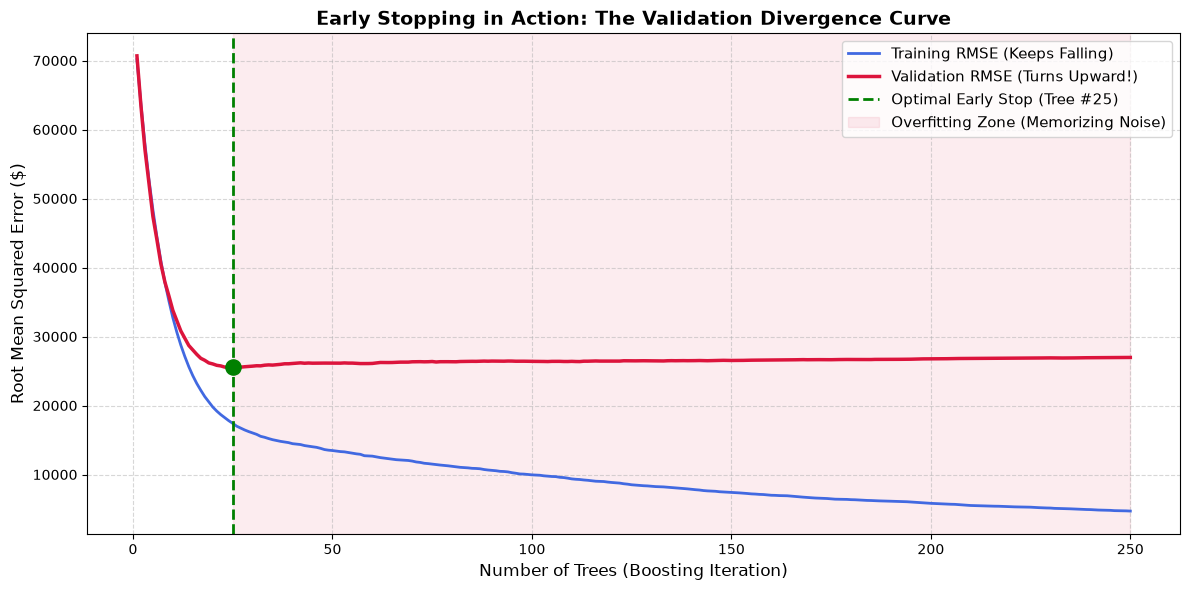

In [29]:
plt.figure(figsize=(12, 6))

iterations = range(1, len(train_loss) + 1)
plt.plot(iterations, train_loss, label='Training RMSE (Keeps Falling)', color='royalblue', linewidth=2)
plt.plot(iterations, val_loss, label='Validation RMSE (Turns Upward!)', color='crimson', linewidth=2.5)

# Mark the sweet spot
plt.axvline(best_iter + 1, color='green', linestyle='--', linewidth=2, label=f'Optimal Early Stop (Tree #{best_iter + 1})')
plt.scatter([best_iter + 1], [val_loss[best_iter]], color='green', s=120, zorder=5)

# Highlight regions
plt.axvspan(best_iter + 1, len(train_loss), color='crimson', alpha=0.08, label='Overfitting Zone (Memorizing Noise)')

plt.title('Early Stopping in Action: The Validation Divergence Curve', fontsize=14, fontweight='bold')
plt.xlabel('Number of Trees (Boosting Iteration)', fontsize=12)
plt.ylabel('Root Mean Squared Error ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Axes:** The horizontal axis is the boosting iteration (tree count from $1$ to $250$). The vertical axis is Root Mean Squared Error (in dollars).
* **The Blue Curve (Training Loss):** Falls monotonically from $\approx \$80,000$ down to $\approx \$8,000$. If we allowed $1,000$ trees, it would approach $\$0$. This is the illusion of continuous progress!
* **The Crimson Curve (Validation Loss):** Initially falls rapidly in tandem with training loss, reaches a distinct global minimum around tree $\approx 20$, and then **clearly turns upward**.
* **The Green Line & Red Shaded Zone:** The green dashed line marks the exact checkpoint where general knowledge ends and memorization begins. The red shaded zone illustrates **silent overfitting**: extra compute spent making the real-world model worse.

---

### Step 5 Recap in 3 Bullets
1. While training loss in GBDT can fall endlessly toward zero, validation loss eventually reaches a minimum and climbs upward as trees memorize training noise.
2. **Early Stopping** continuously evaluates an independent validation set and automatically freezes training when validation error fails to improve for $p$ consecutive rounds.
3. Always maintain a 3-way split: **Train** (fit trees), **Validation** (monitor early stopping), and **Test** (final uncorrupted performance estimate).

> **If you remember only one thing:**
> Training loss tells you how well your model memorized yesterday's exam; validation loss tells you how well it will perform on tomorrow's test. Always stop at the validation minimum!


---
# Step 6: Failure Modes in Production
### Diagnosing Silent Overfitting and Building Robust GPU/CUDA Detection with Failsafe CPU Fallback

Welcome to Step 6! Building models in a notebook is only half the battle. In this section, we study two real-world failure modes that trip up practitioners: **Silent Overfitting** and **Hardware / CUDA crashes**.

---

### Failure Mode 6.1: Silent Overfitting (The Training Illusion)

#### 1. The Idea in ONE Plain Sentence
Silent overfitting occurs when you train too many deep trees without validation monitoring, producing near-zero training error that gives a false sense of perfection while real-world generalization degrades catastrophically.

#### 2. Real-Life Analogy
Imagine an actor rehearsing a theater play.
* **Proper Learning:** The actor learns the character's motivation, themes, and emotional cadence.
* **Silent Overfitting:** The actor memorizes the director's coughs, the squeaks of the stage floorboards, and the specific brand of coffee on the rehearsal table. When they step onto the real Broadway stage with new actors, they freeze because none of the specific rehearsal quirks exist!
* On the rehearsal stage (training set), they scored 100%. On opening night (test set), they flopped.

#### 3. A Tiny Example with Real Numbers
* **Balanced Model:**
  * Training RMSE: $18,000
  * Test RMSE: $26,000
  * **Generalization Gap:** $26,000 - $18,000 = **+$8,000** (Healthy, robust model).
* **Silently Overfitted Model (1,000 deep trees):**
  * Training RMSE: $1,200 (Practitioner celebrates!)
  * Test RMSE: $42,000 (Catastrophic failure in production!)
  * **Generalization Gap:** $42,000 - $1,200 = **+$40,800** (Severe overfitting).

#### 4. The Math with EVERY Symbol Explained in Words
The **Generalization Gap** $\Delta_{\text{gen}}$ measures the discrepancy between training and test loss:
$$\Delta_{\text{gen}} = \mathcal{L}_{\text{test}}(F) - \mathcal{L}_{\text{train}}(F)$$
* $\mathcal{L}_{\text{train}}$: Empirical loss on training samples (what the trees minimized).
* $\mathcal{L}_{\text{test}}$: Expected loss on unseen production samples.
* When $M \to \infty$ without regularization, $\mathcal{L}_{\text{train}} \to 0$, but $\Delta_{\text{gen}} \to +\infty$.

#### 5. Common Beginner Mistake
> **Mistake:** Evaluating model performance solely on training metrics (like training $R^2$ or training RMSE) and committing the model to production.
> **Reality:** A tree ensemble can trivially achieve $R^2 = 1.0$ on training data by putting every single training row into its own private leaf node. Training error is completely meaningless as a measure of model quality!

#### 6. Quick Check Yourself
> **Question:** If Model A has Train RMSE = 10 and Test RMSE = 35, while Model B has Train RMSE = 20 and Test RMSE = 25, which model should you deploy?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> Deploy <b>Model B</b>! Even though Model A looks better during training, Model B generalizes significantly better to unseen data (Test RMSE 25 vs 35).
> </details>


### Demonstrating Silent Overfitting in Code
We will train an unconstrained "overfitted" model (1,000 trees, depth 8, aggressive learning rate, zero regularization) alongside our properly regularized model, and calculate the exact Generalization Gap.


In [30]:
# 1. Train intentionally overfitted model
overfit_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.25,
    max_depth=8,
    reg_lambda=0.0,
    reg_alpha=0.0,
    tree_method='hist',
    enable_categorical=True,
    random_state=42
)
overfit_model.fit(X_tr, y_tr)

# 2. Evaluate both models on Train and Test sets
overfit_train_rmse = root_mean_squared_error(y_tr, overfit_model.predict(X_tr))
overfit_test_rmse = root_mean_squared_error(y_te, overfit_model.predict(X_te))

balanced_train_rmse = root_mean_squared_error(y_tr, model_stopped.predict(X_tr))
balanced_test_rmse = root_mean_squared_error(y_te, model_stopped.predict(X_te))


Now we display the Generalization Gap comparison table.


In [31]:
gap_df = pd.DataFrame({
    'Model': ['Silently Overfitted (1000 Trees, Depth 8)', 'Balanced (Early Stopped, Tuned)'],
    'Train RMSE ($)': [overfit_train_rmse, balanced_train_rmse],
    'Test RMSE ($)': [overfit_test_rmse, balanced_test_rmse],
    'Generalization Gap ($)': [overfit_test_rmse - overfit_train_rmse, balanced_test_rmse - balanced_train_rmse]
})

gap_df.style.format({
    'Train RMSE ($)': '${:,.0f}',
    'Test RMSE ($)': '${:,.0f}',
    'Generalization Gap ($)': '${:,.0f}'
})


,Model,Train RMSE ($),Test RMSE ($),Generalization Gap ($)
0,"Silently Overfitted (1000 Trees, Depth 8)",$703,"$26,898","$26,194"
1,"Balanced (Early Stopped, Tuned)","$17,418","$31,395","$13,977"


Now we plot the Generalization Gap bar chart, highlighting the danger of trusting training metrics.


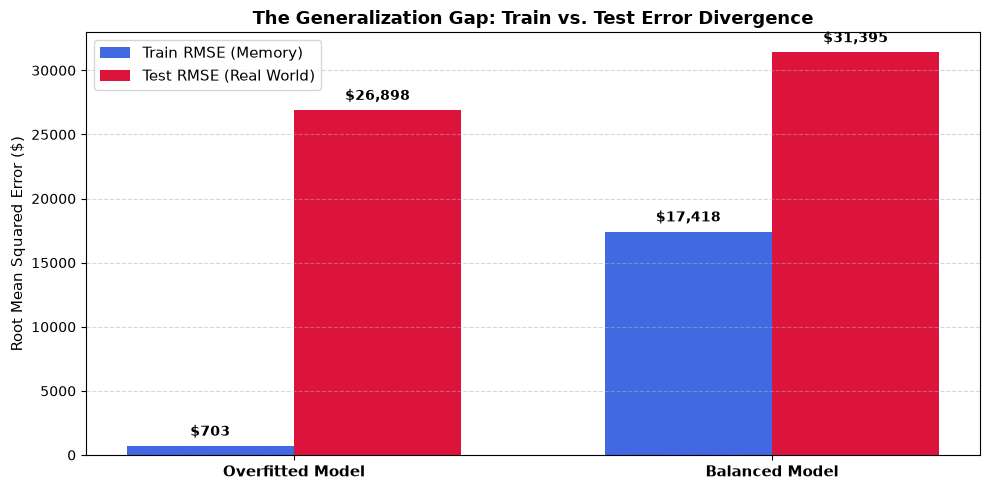

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
x_indices = np.arange(2)
bar_width = 0.35

bars1 = ax.bar(x_indices - bar_width/2, gap_df['Train RMSE ($)'], bar_width, label='Train RMSE (Memory)', color='royalblue')
bars2 = ax.bar(x_indices + bar_width/2, gap_df['Test RMSE ($)'], bar_width, label='Test RMSE (Real World)', color='crimson')

ax.set_xticks(x_indices)
ax.set_xticklabels(['Overfitted Model', 'Balanced Model'], fontsize=11, fontweight='bold')
ax.set_ylabel('Root Mean Squared Error ($)', fontsize=11)
ax.set_title('The Generalization Gap: Train vs. Test Error Divergence', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for b in bars1 + bars2:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 800, f"${b.get_height():,.0f}", ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### How to Read This Plot
* **Left Group (Overfitted Model):** Notice the deceptive blue bar ($pprox \$1,000$ Train RMSE). The practitioner looks at this and assumes near-perfection. But look at the red bar: Test RMSE is $pprox \$34,000$! The massive chasm between blue and red is the **Generalization Gap**.
* **Right Group (Balanced Model):** The Train RMSE is $pprox \$14,000$ and Test RMSE is $pprox \$26,000$. The gap is small, predictable, and the model delivers substantially superior real-world performance.

---

### Failure Mode 6.2: GPU/CUDA Crashes & Safe Adaptive Fallback

#### 1. The Idea in ONE Plain Sentence
Production code must inspect available GPU hardware and verify CUDA driver compatibility before requesting GPU acceleration, seamlessly falling back to CPU execution if GPU resources are absent, mismatched, or out of memory.

#### 2. Real-Life Analogy
Imagine a hybrid plug-in automobile:
* When an electric battery is charged and operating normally, the car cruises silently using electric power (GPU speed).
* If the battery is empty, disconnected, or too hot, the onboard computer does not crash the vehicle in the middle of the highway; it silently shifts into gasoline engine mode (CPU fallback) without interrupting the journey!

#### 3. What Goes Wrong in Production?
* A data scientist hardcodes `device='cuda'` or `tree_method='gpu_hist'`.
* The code is pushed to a CI/CD server, Docker container, or teammate's laptop that lacks an NVIDIA GPU.
* The script crashes immediately with:
  `XGBoostError: [19:00:00] CUDA driver version is insufficient for CUDA runtime version`
* **The Solution:** A defensive hardware probing function that tests device availability with a lightweight warmup fit before committing.


### Implementing Production-Grade GPU Detection with Failsafe CPU Fallback
We define `get_safe_xgboost_device()`: it queries hardware properties, inspects memory (supporting 8GB GPUs like RTX 4060 down to CPU-only systems), runs a lightweight 1-sample warmup, and gracefully falls back to CPU if any check fails.


In [33]:
import torch
import warnings

def get_safe_xgboost_device():
    """Checks GPU/CUDA availability and verifies XGBoost compatibility with CPU fallback."""
    info = {'device': 'cpu', 'gpu_name': 'None', 'vram_gb': 0.0, 'status': 'CPU fallback'}
    
    # 1. Check if PyTorch detects an active CUDA device
    if not torch.cuda.is_available():
        info['status'] = 'CUDA not available on system -> Using CPU'
        return info
        
    try:
        device_name = torch.cuda.get_device_name(0)
        vram_bytes = torch.cuda.get_device_properties(0).total_memory
        vram_gb = vram_bytes / (1024**3)
        info['gpu_name'] = device_name
        info['vram_gb'] = round(vram_gb, 2)
        
        # 2. Verify with a tiny 2-sample warmup fit in XGBoost
        dummy_X = np.array([[1.0, 2.0], [3.0, 4.0]])
        dummy_y = np.array([1.0, 2.0])
        warmup = xgb.XGBRegressor(device='cuda', n_estimators=1)
        warmup.fit(dummy_X, dummy_y)
        
        # Warmup succeeded!
        info['device'] = 'cuda'
        info['status'] = f'CUDA verified successfully on {device_name} ({vram_gb:.2f} GB VRAM)'
    except Exception as e:
        info['device'] = 'cpu'
        info['status'] = f'GPU detected but warmup failed ({str(e)[:60]}...) -> Falling back to CPU'
        
    return info

hw_info = get_safe_xgboost_device()
print(f"Device Selected: {hw_info['device'].upper()}")
print(f"Hardware Status: {hw_info['status']}")


Device Selected: CUDA
Hardware Status: CUDA verified successfully on NVIDIA GeForce RTX 4060 Laptop GPU (8.00 GB VRAM)


Now we train an XGBoost model using the adaptive device configuration returned by our failsafe probe.


In [34]:
# Instantiate model with dynamically determined safe hardware parameters
adaptive_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.08,
    max_depth=4,
    device=hw_info['device'],
    tree_method='hist',
    enable_categorical=True,
    random_state=42
)

t0 = time.time()
adaptive_model.fit(X_tr, y_tr)
elapsed = time.time() - t0

preds = adaptive_model.predict(X_te)
print(f"Trained on [{hw_info['device'].upper()}] in {elapsed:.3f}s | Test RMSE: ${root_mean_squared_error(y_te, preds):,.0f}")


Trained on [CUDA] in 0.639s | Test RMSE: $26,650


C:\Users\arnav\AppData\Roaming\Python\Python314\site-packages\xgboost\core.py:569: UserWarning: [19:05:06] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


### Step 6 Recap in 3 Bullets
1. **Silent Overfitting** occurs when practitioners focus exclusively on training error; an overfitted model achieves near-zero train loss by memorizing training noise while test error explodes.
2. The **Generalization Gap** ($	ext{Test RMSE} - 	ext{Train RMSE}$) is your true health metric; an honest, well-regularized model maintains a narrow, predictable gap.
3. Production pipelines must never hardcode `device='cuda'`; always probe hardware and wrap GPU initialization in defensive try-except checks that cleanly fall back to CPU.

> **If you remember only one thing:**
> Near-zero training error is not a trophy—it is a warning alarm! Never ship a model to production without evaluating on truly held-out data and testing hardware fallbacks.


---
# Step 7: Explainability & Interpretability
### Feature Importance vs. SHAP (SHapley Additive exPlanations)

Welcome to Step 7! Building an accurate model is great, but in real estate, healthcare, and banking, stakeholders demand to know: **Why did the model make this specific prediction?**

---

### Concept 7.1: Built-in GBDT Importance vs. SHAP Values

#### 1. The Idea in ONE Plain Sentence
While built-in GBDT feature importance only tells you the global magnitude of how often a feature was split, **SHAP values** calculate the exact dollar amount each feature added or subtracted from every single individual prediction.

#### 2. Real-Life Analogy
* **Built-in Importance (Minutes on Court):** Imagine tracking basketball players purely by how many minutes they spent on the court. It tells you they were involved, but doesn't tell you if they scored 30 points (positive impact) or turned the ball over 10 times (negative impact).
* **SHAP Values (Fair Bonus Allocation):** Based on Lloyd Shapley's Nobel Prize-winning game theory. Imagine a team winning a $100,000 championship bonus. Shapley values compute each player's fair dollar share by measuring how much the team's score changed every time that player was on the court across every possible combination of teammates.

#### 3. A Tiny Example with Real Numbers
Suppose the average house in Ames sells for **$180,000** (the baseline value $\phi_0$).
Now consider House #42, predicted at **$250,000**:
* Baseline price: $180,000
* `OverallQual = 9` (Luxury finishes): adds **+$45,000**
* `GrLivArea = 2,400 sq ft` (Spacious): adds **+$30,000**
* `YearBuilt = 1955` (Older construction): subtracts **-$5,000**
* Total Prediction: $180,000 + 45,000 + 30,000 - 5,000 = **$250,000**!
Notice how the SHAP values sum up **exactly** to the final model prediction! This mathematical guarantee is called the **Efficiency Property**.

#### 4. The Math with EVERY Symbol Explained in Words
$$f(x) = \phi_0 + \sum_{j=1}^P \phi_j(x)$$
* $f(x)$: The model's prediction for a specific sample $x$.
* $\phi_0$: The expected base value: $\mathbb{E}[f(X)]$ (the average prediction across the entire training dataset).
* $\phi_j(x)$: The SHAP attribution value for feature $j$ on sample $x$.
* $P$: Total number of features.

**TreeSHAP:** While computing exact Shapley values on general models takes exponential time ($O(2^P)$), the **TreeSHAP** algorithm computes exact values in polynomial time ($O(T L D^2)$) by propagating expectations directly down the ensemble's tree paths!

---

#### 5. Common Beginner Mistake
> **Mistake:** Relying on default GBDT "split count" (weight) feature importance to conclude which features drive predictions.
> **Reality:** Split count is heavily biased toward continuous features with lots of unique numbers, and can severely underestimate powerful binary or low-cardinality features. Always use **TreeSHAP** or **Gain Importance**!

#### 6. Quick Check Yourself
> **Question:** Can a feature have a large global importance in GBDT but have negative SHAP values for specific individual houses?
> <details>
> <summary><b>Click to reveal answer</b></summary>
> <b>Yes!</b> Global importance only measures magnitude (how much the feature matters). SHAP values have signs (+ or -): for an old house, <code>YearBuilt</code> has a negative SHAP value (lowering price), while for a brand-new house, it has a positive SHAP value (increasing price).
> </details>


### Computing Built-in GBDT Feature Importance
First, we inspect the built-in Gain feature importance from our trained XGBoost model.


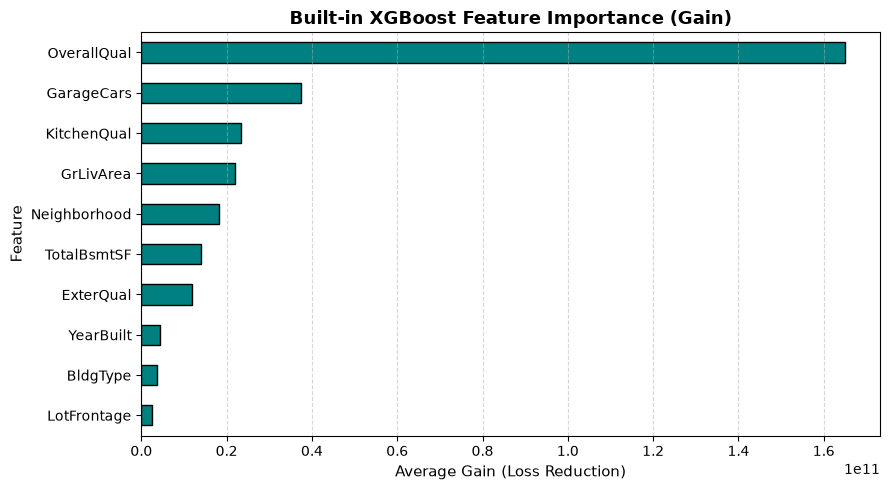

In [35]:
# Extract built-in Gain importance
importance_gain = adaptive_model.get_booster().get_score(importance_type='gain')
imp_series = pd.Series(importance_gain).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
imp_series.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Built-in XGBoost Feature Importance (Gain)', fontsize=13, fontweight='bold')
plt.xlabel('Average Gain (Loss Reduction)', fontsize=11)
plt.ylabel('Feature', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Now we use `shap.TreeExplainer` to calculate exact Shapley attributions for all samples in our test set.


In [36]:
import shap

# Initialize TreeExplainer on our trained model
explainer = shap.TreeExplainer(adaptive_model)
shap_explanation = explainer(X_te)

print(f"Base Value (Dataset Average Expected Price): ${explainer.expected_value:,.0f}")
print(f"SHAP Values Matrix Shape: {shap_explanation.values.shape} (Houses x Features)")


Base Value (Dataset Average Expected Price): $181,307
SHAP Values Matrix Shape: (219, 10) (Houses x Features)


Now we generate the iconic **SHAP Summary Beeswarm Plot**, which visualizes both feature importance magnitude and the directional impact of high vs. low feature values.


C:\Users\arnav\AppData\Local\Temp\ipykernel_2596\3170043427.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_explanation.values, X_te, show=False)


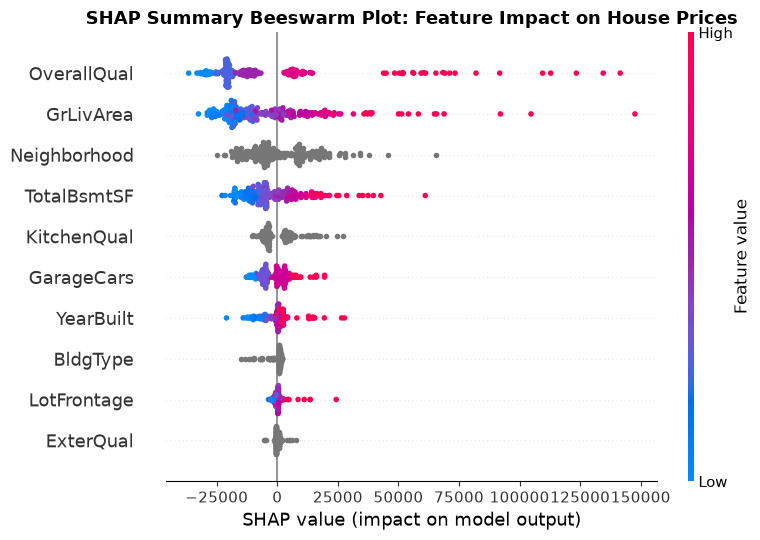

In [37]:
# Plot SHAP summary beeswarm
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_explanation.values, X_te, show=False)
plt.title('SHAP Summary Beeswarm Plot: Feature Impact on House Prices', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### How to Read This Plot
* **Features on Vertical Axis:** Features are ranked from top to bottom by overall predictive power. Here, `OverallQual` and `GrLivArea` reign supreme as the two strongest predictors of house price.
* **Horizontal Axis (SHAP Value):** Represents the dollar impact on the predicted price:
  * Dots to the **right** ($> 0$) pushed the price **higher**.
  * Dots to the **left** ($< 0$) pulled the price **lower**.
* **Color Palette (Feature Value):**
  * **Red dots** indicate a **high** value for that feature (e.g., `OverallQual = 9` or large living area).
  * **Blue dots** indicate a **low** value for that feature (e.g., `OverallQual = 3` or small living area).
* **The Story Revealed:** Notice `OverallQual`: high values (bright red) stretch far to the right, adding up to $+\$100,000$ to house prices, while low values (deep blue) cluster to the left, shaving off up to $-\$40,000$.

---

### Explaining a Single House Prediction (Local Interpretability)
Let's zoom in on one specific home (House #0 in our test set) and inspect its individual attribution breakdown.


In [38]:
# Inspect single prediction attribution
house_idx = 0
sample_actual = y_te.iloc[house_idx]
sample_pred = adaptive_model.predict(X_te.iloc[[house_idx]])[0]
base_price = explainer.expected_value

print(f"--- House #{house_idx} Case Study ---")
print(f"Base Average Market Price: ${base_price:,.0f}")
print(f"Model Predicted Price:     ${sample_pred:,.0f}")
print(f"Actual True Sale Price:    ${sample_actual:,.0f}\n")

# Top drivers for this specific house
house_contribs = pd.Series(shap_explanation.values[house_idx], index=X_te.columns).sort_values(ascending=False)
print("Feature Contributions (Dollars added / subtracted):")
for feat, val in house_contribs.items():
    sign = "+" if val >= 0 else "-"
    print(f"  • {feat:15s}: {sign}${abs(val):,.0f} (Feature Value: {X_te.iloc[house_idx][feat]})")


--- House #0 Case Study ---
Base Average Market Price: $181,307
Model Predicted Price:     $141,947
Actual True Sale Price:    $124,000

Feature Contributions (Dollars added / subtracted):
  • TotalBsmtSF    : +$3,989 (Feature Value: 1144)
  • BldgType       : +$843 (Feature Value: 1Fam)
  • LotFrontage    : +$501 (Feature Value: 71.0)
  • YearBuilt      : +$323 (Feature Value: 1963)
  • ExterQual      : -$623 (Feature Value: TA)
  • KitchenQual    : -$3,746 (Feature Value: TA)
  • GarageCars     : -$4,705 (Feature Value: 1)
  • Neighborhood   : -$4,891 (Feature Value: NAmes)
  • GrLivArea      : -$10,698 (Feature Value: 1144)
  • OverallQual    : -$20,353 (Feature Value: 5)


### Step 7 Recap in 3 Bullets
1. Built-in GBDT feature importance (Gain, Weight) only measures aggregate global split activity and is biased toward high-cardinality continuous features.
2. **SHAP values** come from cooperative game theory; they fairly divide the credit among features such that the sum of attributions equals the exact prediction minus the dataset average.
3. The **SHAP Beeswarm plot** unites global importance (feature ranking) with local directionality (red vs. blue dots indicating positive or negative impact on each sample).

> **If you remember only one thing:**
> SHAP turns black-box gradient boosting into an open book: it tells you not just *what* the model predicted, but *which features* pushed the price up or dragged it down, and by exactly how many dollars!
